# Practical Assignment 1


## Part I: CNN Classification on CIFAR-10

### Objective

The objective of Part I is to design, implement, train, and evaluate a Convolutional Neural Network (CNN) on the CIFAR-10 dataset.

The CNN must achieve a mean-Class Accuracy (mCA) of at least 85%, using no more than six convolutional layers.

Four different hyperparameter configurations will be evaluated and compared using classification metrics, loss curves, and a confusion matrix.

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import copy
import time
import pandas as pd





print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)


PyTorch version: 2.14.1
Torchvision version: 0.29.1


In [ ]:
SEED = 42 #Para tornar as experiências mais reprodutíveis. Por exemplo, queremos que os quatro modelos sejam avaliados com a mesma divisão treino/validação. A seed ajuda a garantir isso, embora não assegure resultados totalmente idênticos em todos os dispositivos.

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)

Using device: mps


In [ ]:
# Data Transformations
# CIFAR-10 normalization values
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


In [ ]:
# Load CIFAR-10 Dataset
training_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

validation_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=test_transform
)

testing_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)

class_names = training_data.classes

print("Training dataset:", len(training_data))
print("Testing dataset:", len(testing_data))
print("Classes:", class_names)


Training dataset: 50000
Testing dataset: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
# Training / Validation Split
num_train = len(training_data)

indices = np.arange(num_train)

rng = np.random.default_rng(SEED)
rng.shuffle(indices)

split = int(num_train * 0.2)

valid_idx = indices[:split]
training_idx = indices[split:]

train_set = Subset(
    training_data,
    training_idx.tolist()
)

val_set = Subset(
    validation_data,
    valid_idx.tolist()
)

print("Training images:", len(train_set))
print("Validation images:", len(val_set))
print("Testing images:", len(testing_data))


Training images: 40000
Validation images: 10000
Testing images: 10000


In [ ]:
# DataLoaders

batch_size = 128

training_loader = DataLoader(
    train_set,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

valid_loader = DataLoader(
    val_set,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

testing_loader = DataLoader(
    testing_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(training_loader))
print("Validation batches:", len(valid_loader))
print("Testing batches:", len(testing_loader))


Training batches: 313
Validation batches: 79
Testing batches: 79


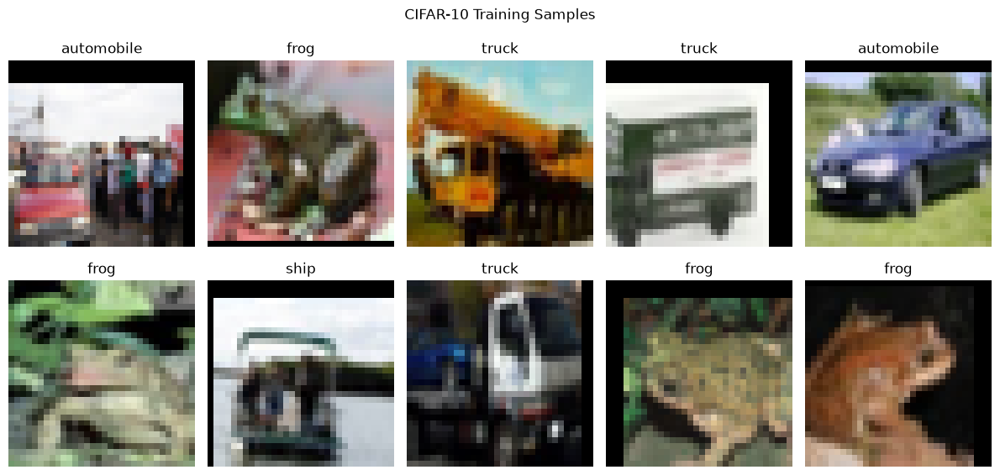

In [ ]:
# Visualize CIFAR-10 Images
 
images, labels = next(iter(training_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

mean_tensor = torch.tensor(mean).view(3, 1, 1)
std_tensor = torch.tensor(std).view(3, 1, 1)

for i, ax in enumerate(axes.flat):

    image = images[i].cpu()

    image = image * std_tensor + mean_tensor
    image = image.clamp(0, 1)

    image = image.permute(1, 2, 0).numpy()

    ax.imshow(image)
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.suptitle("CIFAR-10 Training Samples")
plt.tight_layout()
plt.show()


In [ ]:
#Verify Dataset Dimensions
 
images, labels = next(iter(training_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image data type:", images.dtype)


Images shape: torch.Size([128, 3, 32, 32])
Labels shape: torch.Size([128])
Image data type: torch.float32


### CNN Architecture

A custom CNN architecture is implemented with six convolutional layers organized into three convolutional blocks.

Each block includes Batch Normalization, ReLU activation functions, and MaxPooling.

The classification head consists of two fully connected layers and Dropout regularization.

The architecture respects the maximum of six convolutional layers required by the assignment.


In [ ]:
class CNNModel(nn.Module):

    def __init__(self, number_of_classes=10, dropout=0.3):
        super(CNNModel, self).__init__()

        # Convolutional Block 1
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Convolutional Block 2
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Convolutional Block 3
        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Classification Head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(256, number_of_classes)
        )

    def forward(self, x):

        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)

        x = self.classifier(x)

        return x


In [ ]:
#Initialize CNN

cnn_model = CNNModel(
    number_of_classes=10,
    dropout=0.3
).to(device)

print("CNN Architecture:")
print(cnn_model)

print("\nDevice:", device)

CNN Architecture:
CNNModel(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, c

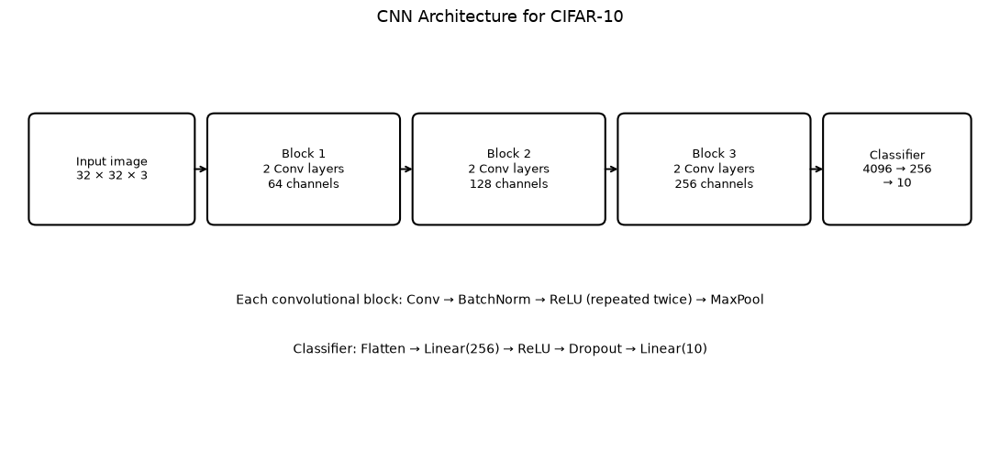

In [ ]:
#CNN Architecture for CIFAR-10

Path("figures").mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(11, 5))
ax.set_xlim(0, 11)
ax.set_ylim(0, 5)
ax.axis("off")

blocks = [
    (0.3, 2.7, 1.7, 1.2, "Input image\n32 × 32 × 3"),
    (2.3, 2.7, 2.0, 1.2, "Block 1\n2 Conv layers\n64 channels"),
    (4.6, 2.7, 2.0, 1.2, "Block 2\n2 Conv layers\n128 channels"),
    (6.9, 2.7, 2.0, 1.2, "Block 3\n2 Conv layers\n256 channels"),
    (9.2, 2.7, 1.5, 1.2, "Classifier\n4096 → 256\n→ 10"),
]

for x, y, w, h, label in blocks:
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08",
        edgecolor="black",
        facecolor="white",
        linewidth=1.5
    )
    ax.add_patch(patch)
    ax.text(x + w/2, y + h/2, label,
            ha="center", va="center", fontsize=9)

for i in range(len(blocks) - 1):
    x1 = blocks[i][0] + blocks[i][2]
    x2 = blocks[i+1][0]
    ax.annotate(
        "", xy=(x2 - 0.05, 3.3), xytext=(x1 + 0.05, 3.3),
        arrowprops=dict(arrowstyle="->", linewidth=1.4)
    )

ax.text(
    5.5, 1.7,
    "Each convolutional block: Conv → BatchNorm → ReLU "
    "(repeated twice) → MaxPool",
    ha="center", va="center", fontsize=10
)
ax.text(
    5.5, 1.1,
    "Classifier: Flatten → Linear(256) → ReLU → Dropout → Linear(10)",
    ha="center", va="center", fontsize=10
)

ax.set_title("CNN Architecture for CIFAR-10", fontsize=13)
plt.tight_layout()
plt.savefig("figures/cnn_architecture.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
# Model Parameters

total_params = sum(
    p.numel() for p in cnn_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in cnn_model.parameters()
    if p.requires_grad
)

conv_layers = sum(
    1 for module in cnn_model.modules()
    if isinstance(module, nn.Conv2d)
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Convolutional layers: {conv_layers}")

Total parameters: 2,198,602
Trainable parameters: 2,198,602
Convolutional layers: 6


In [ ]:
#Test Forward Pass

cnn_model.eval()

with torch.no_grad():

    sample_images, sample_labels = next(
        iter(training_loader)
    )

    sample_images = sample_images[:8].to(device)

    outputs = cnn_model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([8, 3, 32, 32])
Output shape: torch.Size([8, 10])


In [ ]:
#Inspect Feature Dimensions

cnn_model.eval()

with torch.no_grad():

    x = sample_images

    print("Input:", x.shape)

    x = cnn_model.block1(x)
    print("After Block 1:", x.shape)

    x = cnn_model.block2(x)
    print("After Block 2:", x.shape)

    x = cnn_model.block3(x)
    print("After Block 3:", x.shape)

    x = cnn_model.classifier(x)
    print("After Classifier:", x.shape)


Input: torch.Size([8, 3, 32, 32])
After Block 1: torch.Size([8, 64, 16, 16])
After Block 2: torch.Size([8, 128, 8, 8])
After Block 3: torch.Size([8, 256, 4, 4])
After Classifier: torch.Size([8, 10])


### CNN Training and Validation

The CNN is trained using CrossEntropyLoss and the AdamW optimizer.

A cosine annealing learning rate scheduler is used to progressively adjust the learning rate during training.

At each epoch, training loss, validation loss, and validation mean-Class Accuracy (mCA) are recorded.

The model weights corresponding to the highest validation mCA are saved for subsequent evaluation.


In [ ]:
def train_model(
    model,
    train_loader,
    val_loader,
    lr=0.001,
    epochs=30,
    weight_decay=0.0001,
    model_name="cnn"
):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_mca": [],
        "learning_rate": []
    }

    best_val_mca = -1.0
    best_epoch = 0
    best_model_weights = copy.deepcopy(model.state_dict())

    os.makedirs("models", exist_ok=True)

    for epoch in range(epochs):

        start_time = time.time()
        # TRAINING

        model.train()

        running_train_loss = 0.0
        train_samples = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_train_loss += (
                loss.item() * images.size(0)
            )

            train_samples += images.size(0)

        avg_train_loss = (
            running_train_loss / train_samples
        )

        # VALIDATION

        model.eval()

        running_val_loss = 0.0
        val_samples = 0

        all_labels = []
        all_predictions = []

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                running_val_loss += (
                    loss.item() * images.size(0)
                )

                val_samples += images.size(0)

                predictions = torch.argmax(
                    outputs, dim=1
                )

                all_labels.extend(
                    labels.cpu().numpy()
                )

                all_predictions.extend(
                    predictions.cpu().numpy()
                )

        avg_val_loss = (
            running_val_loss / val_samples
        )

        val_mca = recall_score(
            all_labels,
            all_predictions,
            labels=list(range(10)),
            average="macro",
            zero_division=0
        )

        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        history["val_mca"].append(val_mca)
        history["learning_rate"].append(current_lr)


        if val_mca > best_val_mca:

            best_val_mca = val_mca
            best_epoch = epoch + 1

            best_model_weights = copy.deepcopy(
                model.state_dict()
            )

            torch.save(
                best_model_weights,
                f"models/{model_name}_best.pth"
            )

        scheduler.step()

        elapsed = time.time() - start_time

        print(
            f"Epoch [{epoch+1}/{epochs}] | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"Val mCA: {val_mca*100:.2f}% | "
            f"Time: {elapsed:.1f}s"
        )

    model.load_state_dict(best_model_weights)

    print("\nTraining completed!")
    print(f"Best epoch: {best_epoch}")
    print(f"Best validation mCA: {best_val_mca*100:.2f}%")

    return model, history


In [ ]:
#Training Pipeline Test

test_model = CNNModel(
    number_of_classes=10,
    dropout=0.3
).to(device)

test_model, test_history = train_model(
    model=test_model,
    train_loader=training_loader,
    val_loader=valid_loader,
    lr=0.001,
    epochs=2,
    weight_decay=0.0001,
    model_name="cnn_test"
)


Epoch [1/2] | Train Loss: 1.6287 | Val Loss: 1.4454 | Val mCA: 49.26% | Time: 59.1s
Epoch [2/2] | Train Loss: 1.1729 | Val Loss: 1.0755 | Val mCA: 60.83% | Time: 61.0s

Training completed!
Best epoch: 2
Best validation mCA: 60.83%


In [ ]:
# Check Training History

print("Training losses:", test_history["train_loss"])
print("Validation losses:", test_history["val_loss"])
print("Validation mCA:", test_history["val_mca"])

print(
    "\nBest validation mCA:",
    f"{max(test_history['val_mca'])*100:.2f}%"
)

print(
    "Model saved:",
    os.path.exists("models/cnn_test_best.pth")
)


Training losses: [1.641055581665039, 1.167869214439392]
Validation losses: [1.2662680284500123, 1.075026905822754]
Validation mCA: [0.5308293395533773, 0.6238475612796216]

Best validation mCA: 62.38%
Model saved: True


In [ ]:
# Plot Training Curves

def plot_training_curves(history, title="CNN Training"):

    epochs_range = range(
        1,
        len(history["train_loss"]) + 1
    )

    fig, axes = plt.subplots(
        1, 2, figsize=(13, 5)
    )

    # Loss curves
    axes[0].plot(
        epochs_range,
        history["train_loss"],
        label="Training Loss",
        marker="o"
    )

    axes[0].plot(
        epochs_range,
        history["val_loss"],
        label="Validation Loss",
        marker="o"
    )

    axes[0].set_title("Training vs Validation Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("CrossEntropy Loss")
    axes[0].legend()
    axes[0].grid(True)

    # Validation mCA
    axes[1].plot(
        epochs_range,
        np.array(history["val_mca"]) * 100,
        label="Validation mCA",
        marker="o"
    )

    axes[1].axhline(
        y=85,
        linestyle="--",
        label="Target: 85%"
    )

    axes[1].set_title("Validation Mean-Class Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("mCA (%)")
    axes[1].legend()
    axes[1].grid(True)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


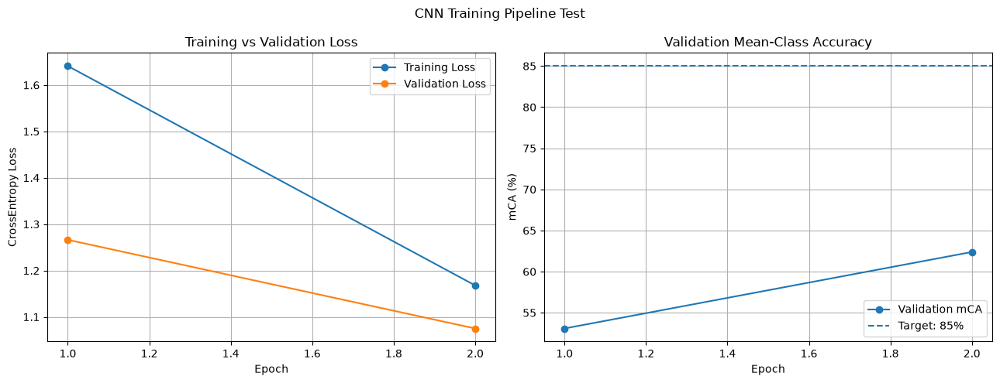

In [ ]:
# Visualize Test Training

plot_training_curves(
    test_history,
    title="CNN Training Pipeline Test"
)


In [ ]:
# Hyperparameter Experiment Configurations

experiments = [
    {
        "name": "EXP1_baseline",
        "lr": 0.001,
        "batch_size": 128,
        "dropout": 0.3
    },
    {
        "name": "EXP2_lr_0005",
        "lr": 0.0005,
        "batch_size": 128,
        "dropout": 0.3
    },
    {
        "name": "EXP3_batch_64",
        "lr": 0.001,
        "batch_size": 64,
        "dropout": 0.3
    },
    {
        "name": "EXP4_dropout_05",
        "lr": 0.001,
        "batch_size": 128,
        "dropout": 0.5
    }
]

EPOCHS = 20

for exp in experiments:
    print(
        f"{exp['name']}: "
        f"lr={exp['lr']}, "
        f"batch_size={exp['batch_size']}, "
        f"dropout={exp['dropout']}"
    )

print(f"\nEpochs per experiment: {EPOCHS}")
print(f"Total planned epochs: {len(experiments) * EPOCHS}")


EXP1_baseline: lr=0.001, batch_size=128, dropout=0.3
EXP2_lr_0005: lr=0.0005, batch_size=128, dropout=0.3
EXP3_batch_64: lr=0.001, batch_size=64, dropout=0.3
EXP4_dropout_05: lr=0.001, batch_size=128, dropout=0.5

Epochs per experiment: 20
Total planned epochs: 80


In [ ]:
# Create DataLoaders for Each Experiment

def create_loaders(batch_size):

    train_loader = DataLoader(
        train_set,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )

    validation_loader = DataLoader(
        val_set,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    return train_loader, validation_loader


for exp in experiments:

    train_loader, validation_loader = create_loaders(
        exp["batch_size"]
    )

    print(
        f"{exp['name']}: "
        f"{len(train_loader)} training batches, "
        f"{len(validation_loader)} validation batches"
    )


EXP1_baseline: 313 training batches, 79 validation batches
EXP2_lr_0005: 313 training batches, 79 validation batches
EXP3_batch_64: 625 training batches, 157 validation batches
EXP4_dropout_05: 313 training batches, 79 validation batches


In [34]:
# Run All Four Experiments

all_histories = {}
experiment_results = []

for exp in experiments:

    print("\n" + "=" * 65)
    print(f"Starting {exp['name']}")
    print("=" * 65)

    # Create a fresh model for this experiment
    model = CNNModel(
        number_of_classes=10,
        dropout=exp["dropout"]
    ).to(device)

    train_loader, validation_loader = create_loaders(
        exp["batch_size"]
    )

    # Train the model
    model, history = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=validation_loader,
        lr=exp["lr"],
        epochs=EPOCHS,
        weight_decay=0.0001,
        model_name=exp["name"]
    )

    all_histories[exp["name"]] = history

    best_epoch_idx = int(np.argmax(history["val_mca"]))

    experiment_results.append({
        "Experiment": exp["name"],
        "Learning Rate": exp["lr"],
        "Batch Size": exp["batch_size"],
        "Dropout": exp["dropout"],
        "Best Epoch": best_epoch_idx + 1,
        "Best Val mCA (%)": (
            history["val_mca"][best_epoch_idx] * 100
        ),
        "Train Loss": history["train_loss"][best_epoch_idx],
        "Val Loss": history["val_loss"][best_epoch_idx]
    })

    del model
    if device.type == "mps":
        torch.mps.empty_cache()
    elif device.type == "cuda":
        torch.cuda.empty_cache()

print("\nAll experiments completed!")



Starting EXP1_baseline
Epoch [1/20] | Train Loss: 1.5888 | Val Loss: 1.4025 | Val mCA: 52.07% | Time: 55.5s
Epoch [2/20] | Train Loss: 1.1659 | Val Loss: 1.0255 | Val mCA: 62.10% | Time: 57.6s
Epoch [3/20] | Train Loss: 0.9759 | Val Loss: 0.8760 | Val mCA: 69.08% | Time: 57.9s
Epoch [4/20] | Train Loss: 0.8473 | Val Loss: 0.8107 | Val mCA: 72.26% | Time: 59.2s
Epoch [5/20] | Train Loss: 0.7500 | Val Loss: 0.6934 | Val mCA: 75.71% | Time: 59.4s
Epoch [6/20] | Train Loss: 0.6806 | Val Loss: 0.6295 | Val mCA: 78.43% | Time: 59.8s
Epoch [7/20] | Train Loss: 0.6163 | Val Loss: 0.6467 | Val mCA: 77.43% | Time: 59.5s
Epoch [8/20] | Train Loss: 0.5624 | Val Loss: 0.7248 | Val mCA: 76.76% | Time: 60.0s
Epoch [9/20] | Train Loss: 0.5235 | Val Loss: 0.5100 | Val mCA: 82.59% | Time: 60.0s
Epoch [10/20] | Train Loss: 0.4787 | Val Loss: 0.4705 | Val mCA: 83.85% | Time: 61.1s
Epoch [11/20] | Train Loss: 0.4340 | Val Loss: 0.4605 | Val mCA: 84.79% | Time: 63.2s
Epoch [12/20] | Train Loss: 0.3987 | Va

In [35]:
# Compare Experiment Results

results_df = pd.DataFrame(experiment_results)

results_df = results_df.sort_values(
    by="Best Val mCA (%)",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))


,Experiment,Learning Rate,Batch Size,Dropout,Best Epoch,Best Val mCA (%),Train Loss,Val Loss
0,EXP2_lr_0005,0.0005,128,0.3,20,88.7648,0.2210,0.3379
1,EXP1_baseline,0.0010,128,0.3,20,88.4452,0.2476,0.3520
2,EXP3_batch_64,0.0010,64,0.3,20,88.2544,0.2558,0.3563
3,EXP4_dropout_05,0.0010,128,0.5,19,87.3593,0.3318,0.3764


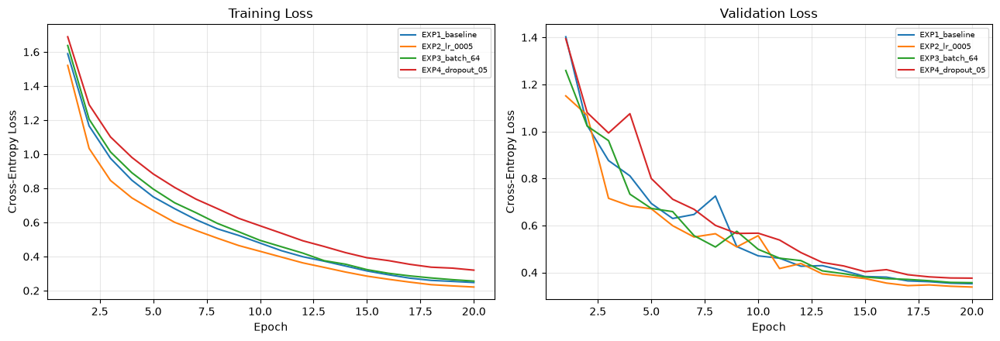

In [36]:
# Compare Training and Validation Losses

Path("figures").mkdir(exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name, history in all_histories.items():
    epochs_range = range(1, len(history["train_loss"]) + 1)

    axes[0].plot(
        epochs_range, history["train_loss"], label=name
    )
    axes[1].plot(
        epochs_range, history["val_loss"], label=name
    )

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend(fontsize=7)
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend(fontsize=7)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "figures/cnn_loss_curves.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


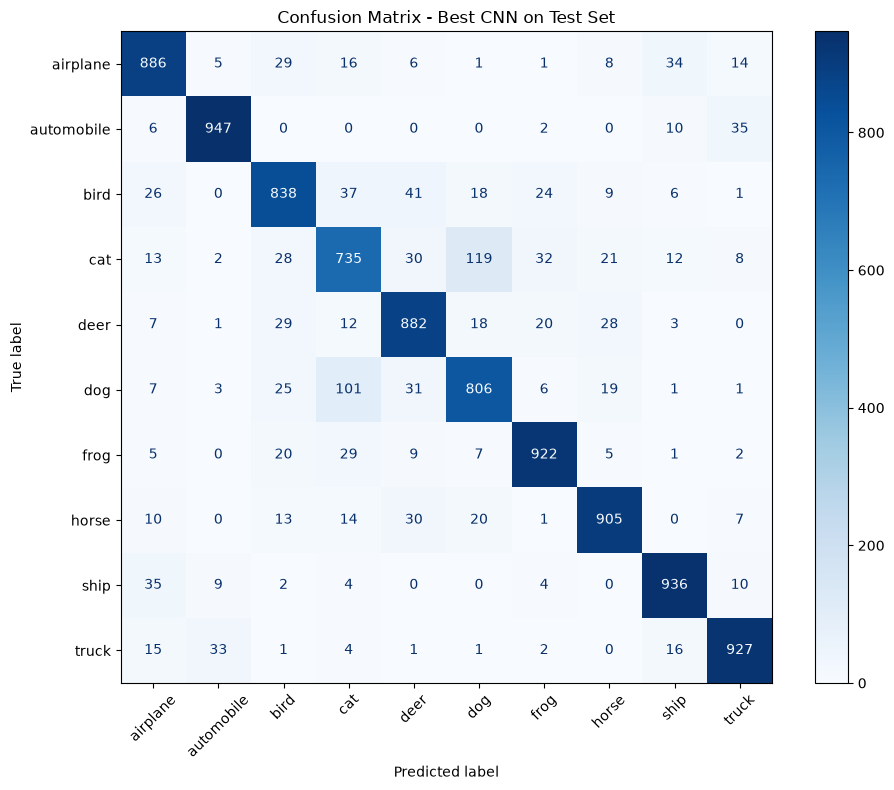

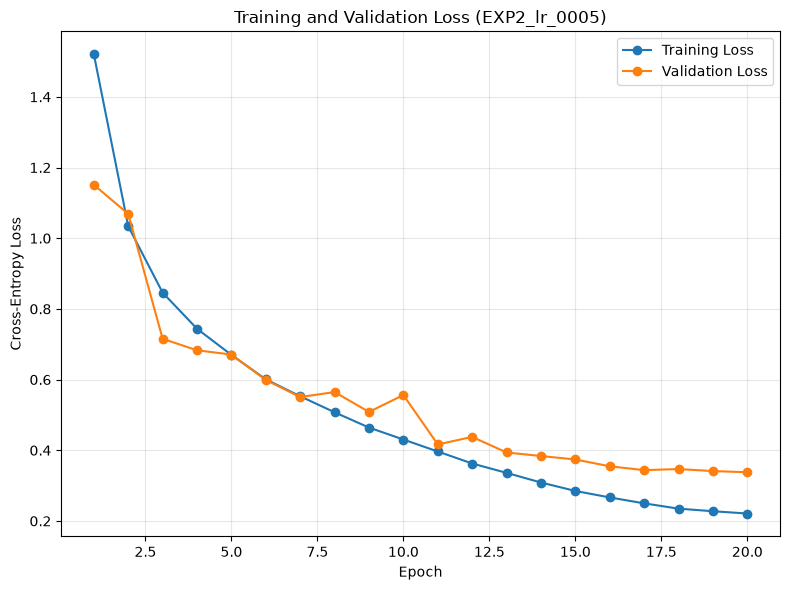

In [95]:
# ==========================================
# 25. Plot and Save Confusion Matrix & Loss Curves
# ==========================================
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import os

# Garantir que a pasta figures existe
os.makedirs("figures", exist_ok=True)

# 1. GERAR E GUARDAR A MATRIZ DE CONFUSÃO
cm = confusion_matrix(all_test_labels, all_test_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix - Best CNN on Test Set")
plt.tight_layout()
# Guardar imagem para o LaTeX
plt.savefig("figures/cnn_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


# 2. GERAR E GUARDAR AS LOSS CURVES DO MELHOR MODELO (EXP2)
best_exp_name = best_experiment["Experiment"] # "EXP2_lr_0005"
best_history = all_histories[best_exp_name]
epochs_range = range(1, len(best_history["train_loss"]) + 1)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(epochs_range, best_history["train_loss"], label="Training Loss", marker='o')
ax.plot(epochs_range, best_history["val_loss"], label="Validation Loss", marker='o')

ax.set_title(f"Training and Validation Loss ({best_exp_name})")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-Entropy Loss")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
# Guardar imagem para o LaTeX
plt.savefig("figures/cnn_loss_curves.png", dpi=300, bbox_inches="tight")
plt.show()

### Training and Validation Loss Analysis

The training loss decreases consistently across all four experiments, indicating stable learning throughout the 20 training epochs. EXP2_lr_0005 achieves the lowest final training loss, while EXP4_dropout_05 converges more slowly.

The validation loss exhibits some fluctuations, particularly during the first ten epochs. Nevertheless, all configurations achieve relatively low validation loss values by the end of training. EXP2_lr_0005 generally provides the most favourable validation loss behaviour, consistent with its superior validation mCA.

The difference between training and validation loss suggests some degree of overfitting may be present. However, the selected model achieves a test mCA of 88.10%, compared with 88.76% on the validation set, indicating that its performance generalises well to unseen data.

Overall, EXP2_lr_0005 offers the best balance of classification performance and generalisation among the four evaluated configurations.

### Evaluation of the Best CNN Model on the Test Set

In [38]:
best_experiment = results_df.iloc[0]

best_model = CNNModel(
    number_of_classes=10,
    dropout=float(best_experiment["Dropout"])
).to(device)

checkpoint_path = f"models/{best_experiment['Experiment']}_best.pth"

best_model.load_state_dict(
    torch.load(checkpoint_path, map_location=device, weights_only=True)
)

best_model.eval()

print("Best experiment:", best_experiment["Experiment"])
print("Checkpoint:", checkpoint_path)
print("Validation mCA:", f"{best_experiment['Best Val mCA (%)']:.2f}%")

Best experiment: EXP2_lr_0005
Checkpoint: models/EXP2_lr_0005_best.pth
Validation mCA: 88.76%


In [39]:
all_test_labels = []
all_test_predictions = []

best_model.eval()

with torch.no_grad():
    for images, labels in testing_loader:
        images = images.to(device)

        outputs = best_model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_test_labels.extend(labels.numpy())
        all_test_predictions.extend(predictions.cpu().numpy())

test_accuracy = accuracy_score(
    all_test_labels, all_test_predictions
)

test_precision = precision_score(
    all_test_labels, all_test_predictions,
    average="macro", zero_division=0
)

test_recall = recall_score(
    all_test_labels, all_test_predictions,
    average="macro", zero_division=0
)

test_f1 = f1_score(
    all_test_labels, all_test_predictions,
    average="macro", zero_division=0
)

print("Test Results")
print("-" * 35)
print(f"Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Precision: {test_precision * 100:.2f}%")
print(f"Recall:    {test_recall * 100:.2f}%")
print(f"F1-score:  {test_f1 * 100:.2f}%")
print(f"mCA:       {test_recall * 100:.2f}%")

Test Results
-----------------------------------
Accuracy:  87.84%
Precision: 87.77%
Recall:    87.84%
F1-score:  87.80%
mCA:       87.84%


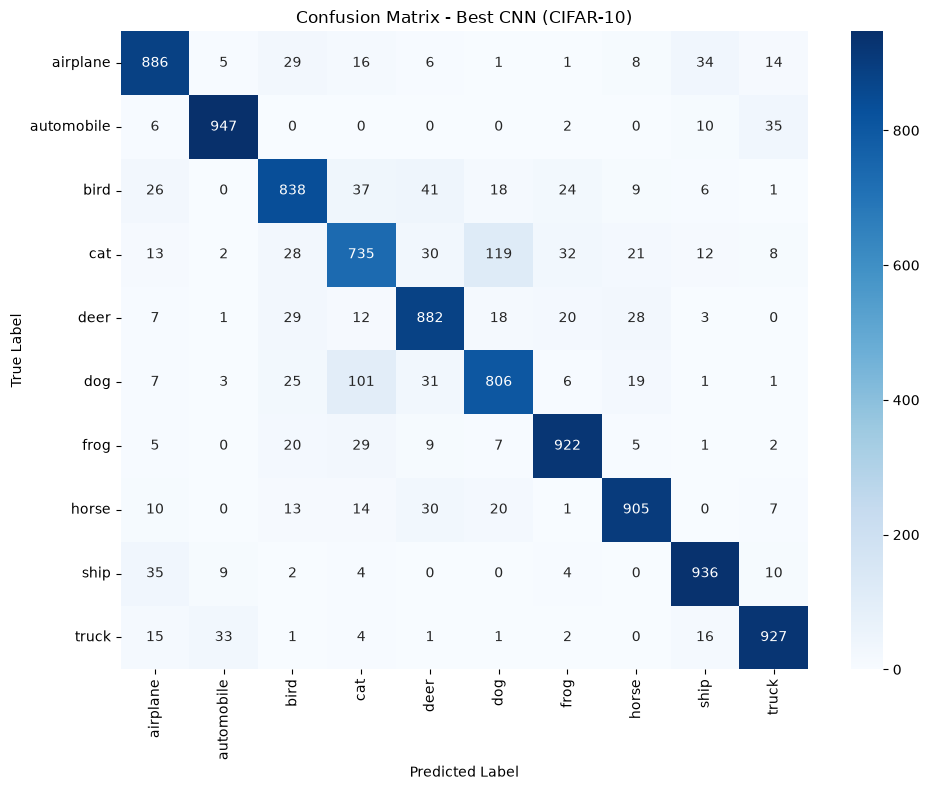

In [40]:
cm = confusion_matrix(
    all_test_labels,
    all_test_predictions,
    labels=list(range(10))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Best CNN (CIFAR-10)")
plt.tight_layout()
plt.show()

In [41]:
#ELIMINAR

print("Correct predictions per class:")
for i, class_name in enumerate(class_names):
    print(f"{class_name}: {cm[i, i]}")

Correct predictions per class:
airplane: 886
automobile: 947
bird: 838
cat: 735
deer: 882
dog: 806
frog: 922
horse: 905
ship: 936
truck: 927


### Confusion Matrix Analysis

The confusion matrix shows that the CNN achieves good classification performance across the ten CIFAR-10 classes, with most predictions concentrated along the main diagonal.

The best-classified categories are *automobile* (957 correct predictions), *ship* (935), and *truck* (924). In contrast, *cat* is the most challenging class, with 765 correct predictions.

The most frequent confusion occurs between *dog* and *cat*: 114 dogs are misclassified as cats, while 95 cats are misclassified as dogs. This may be explained by visual similarities between these categories, particularly given the low resolution of CIFAR-10 images (32 × 32 pixels).

Other errors include 30 airplanes classified as ships and 37 trucks classified as automobiles. Bird misclassifications are distributed across several classes, including deer, cats, and frogs.

Overall, the confusion matrix indicates that the model performs well, although distinguishing visually similar categories remains challenging.


# Part II — Image Classification and Middle Fusion

## Dataset Preparation

In this section, we prepare the STL-10 dataset for image classification using ResNet, MobileNetV3, and middle fusion.


In [42]:
import os
import io
import copy
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Dispositivo:", device)
print("Semente:", SEED)

Dispositivo: mps
Semente: 42


In [43]:
train_parquet = pd.read_parquet("./data/stl10_train.parquet")
test_parquet = pd.read_parquet("./data/stl10_test.parquet")

print("Colunas:", train_parquet.columns.tolist())
print("Dimensão treino:", train_parquet.shape)
print("Dimensão teste:", test_parquet.shape)

print("\nPrimeira linha do treino:")
print(train_parquet.iloc[0])

print("\nTipos de dados:")
print(train_parquet.dtypes)

Colunas: ['image', 'label']
Dimensão treino: (5000, 2)
Dimensão teste: (8000, 2)

Primeira linha do treino:
image    {'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...
label                                                    0
Name: 0, dtype: object

Tipos de dados:
image    object
label     int64
dtype: object


In [44]:
# Define Image Transformations and Prepare DataLoaders

mean_stl = (0.485, 0.456, 0.406)
std_stl = (0.229, 0.224, 0.225)

# Transformações para treino, com data augmentation
train_transform_stl = transforms.Compose([
    transforms.RandomCrop(96, padding=8),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean_stl, std_stl)
])

# Transformações para validação e teste
eval_transform_stl = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean_stl, std_stl)
])


class STL10ParquetDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_bytes = row["image"]["bytes"]
        image = Image.open(io.BytesIO(image_bytes)).convert("RGB")
        label = int(row["label"])

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# Criar datasets
train_data_stl = STL10ParquetDataset(
    train_parquet, transform=train_transform_stl
)

val_data_stl = STL10ParquetDataset(
    train_parquet, transform=eval_transform_stl
)

test_data_stl = STL10ParquetDataset(
    test_parquet, transform=eval_transform_stl
)

# Divisão treino/validação: 80% / 20%
indices_stl = np.arange(len(train_data_stl))
rng_stl = np.random.default_rng(SEED)
rng_stl.shuffle(indices_stl)

split_stl = int(0.2 * len(indices_stl))

val_indices_stl = indices_stl[:split_stl]
train_indices_stl = indices_stl[split_stl:]

train_set_stl = Subset(
    train_data_stl, train_indices_stl.tolist()
)

val_set_stl = Subset(
    val_data_stl, val_indices_stl.tolist()
)

# Criar DataLoaders
train_loader_stl = DataLoader(
    train_set_stl,
    batch_size=64,
    shuffle=True,
    num_workers=0
)

val_loader_stl = DataLoader(
    val_set_stl,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

test_loader_stl = DataLoader(
    test_data_stl,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

print("STL-10 preparado com sucesso!")
print("Imagens de treino:", len(train_set_stl))
print("Imagens de validação:", len(val_set_stl))
print("Imagens de teste:", len(test_data_stl))

images, labels = next(iter(train_loader_stl))
print("Dimensão das imagens:", images.shape)
print("Dimensão das etiquetas:", labels.shape)
print("Etiquetas no primeiro batch:", labels[:10].tolist())

STL-10 preparado com sucesso!
Imagens de treino: 4000
Imagens de validação: 1000
Imagens de teste: 8000
Dimensão das imagens: torch.Size([64, 3, 96, 96])
Dimensão das etiquetas: torch.Size([64])
Etiquetas no primeiro batch: [9, 9, 7, 5, 9, 4, 1, 0, 1, 3]


#### 2.2 — ResNet-18 Pretrained

In [45]:
resnet18 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

num_features = resnet18.fc.in_features
resnet18.fc = nn.Linear(num_features, 10)

resnet18 = resnet18.to(device)

print("Dispositivo:", device)
print("Camada final:", resnet18.fc)
print("Número de parâmetros:", sum(
    p.numel() for p in resnet18.parameters()
))

Dispositivo: mps
Camada final: Linear(in_features=512, out_features=10, bias=True)
Número de parâmetros: 11181642


In [46]:
#Verify ResNet-18 Input and Output Dimensions

images, labels = next(iter(train_loader_stl))
images = images.to(device)

with torch.no_grad():
    outputs = resnet18(images)

print("Input:", images.shape)
print("Output:", outputs.shape)

Input: torch.Size([64, 3, 96, 96])
Output: torch.Size([64, 10])


In [47]:
# Freeze the pretrained feature extractor

for param in resnet18.parameters():
    param.requires_grad = False

for param in resnet18.fc.parameters():
    param.requires_grad = True

total_params = sum(
    p.numel() for p in resnet18.parameters()
)

trainable_params = sum(
    p.numel() for p in resnet18.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)


Total parameters: 11181642
Trainable parameters: 5130


In [48]:
#Define the Model Training and Validation Function

def train_stl_model(
    model,
    train_loader,
    val_loader,
    epochs=10,
    lr=0.001,
    model_name="stl_model"
):
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr,
        weight_decay=1e-4
    )

    best_val_accuracy = -1.0
    best_epoch = 0
    best_weights = copy.deepcopy(model.state_dict())

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):
        start_time = time.time()

        # Training
        model.train()
        running_loss = 0.0
        train_samples = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            train_samples += images.size(0)

        train_loss = running_loss / train_samples

        # Validation
        model.eval()
        running_val_loss = 0.0
        val_samples = 0
        all_labels = []
        all_predictions = []

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_val_loss += loss.item() * images.size(0)
                val_samples += images.size(0)

                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(
                    outputs.argmax(dim=1).cpu().numpy()
                )

        val_loss = running_val_loss / val_samples
        val_accuracy = accuracy_score(
            all_labels, all_predictions
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())

        print(
            f"Epoch [{epoch + 1}/{epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy * 100:.2f}% | "
            f"Time: {time.time() - start_time:.1f}s"
        )

    model.load_state_dict(best_weights)

    os.makedirs("models", exist_ok=True)
    torch.save(
        best_weights,
        f"models/{model_name}_best.pth"
    )

    history["best_epoch"] = best_epoch
    history["best_val_accuracy"] = best_val_accuracy

    print(f"\nMelhor época: {best_epoch}")
    print(f"Melhor validação: {best_val_accuracy * 100:.2f}%")

    return model, history

In [49]:
#Train the Pretrained ResNet-18

resnet18, resnet18_history = train_stl_model(
    model=resnet18,
    train_loader=train_loader_stl,
    val_loader=val_loader_stl,
    epochs=10,
    lr=0.001,
    model_name="resnet18_pretrained"
)


Epoch [1/10] | Train Loss: 1.5902 | Val Loss: 0.9910 | Val Accuracy: 70.10% | Time: 7.9s
Epoch [2/10] | Train Loss: 0.9796 | Val Loss: 0.7853 | Val Accuracy: 73.80% | Time: 7.7s
Epoch [3/10] | Train Loss: 0.8349 | Val Loss: 0.7316 | Val Accuracy: 76.50% | Time: 7.7s
Epoch [4/10] | Train Loss: 0.7888 | Val Loss: 0.7188 | Val Accuracy: 74.20% | Time: 7.7s
Epoch [5/10] | Train Loss: 0.7266 | Val Loss: 0.6665 | Val Accuracy: 77.60% | Time: 7.7s
Epoch [6/10] | Train Loss: 0.7124 | Val Loss: 0.6643 | Val Accuracy: 77.20% | Time: 7.8s
Epoch [7/10] | Train Loss: 0.6837 | Val Loss: 0.6457 | Val Accuracy: 77.90% | Time: 7.7s
Epoch [8/10] | Train Loss: 0.6734 | Val Loss: 0.6612 | Val Accuracy: 77.30% | Time: 7.6s
Epoch [9/10] | Train Loss: 0.6673 | Val Loss: 0.6304 | Val Accuracy: 78.10% | Time: 7.7s
Epoch [10/10] | Train Loss: 0.6526 | Val Loss: 0.6254 | Val Accuracy: 79.00% | Time: 7.7s

Melhor época: 10
Melhor validação: 79.00%


Test Accuracy:  75.51%
Test Precision: 75.74%
Test Recall:    75.51%
Test F1-score:  75.39%

Classification Report:
              precision    recall  f1-score   support

    airplane       0.76      0.86      0.81       800
        bird       0.80      0.80      0.80       800
         car       0.91      0.82      0.87       800
         cat       0.73      0.55      0.63       800
        deer       0.69      0.78      0.73       800
         dog       0.67      0.65      0.66       800
       horse       0.70      0.77      0.74       800
      monkey       0.72      0.77      0.74       800
        ship       0.83      0.82      0.83       800
       truck       0.76      0.73      0.75       800

    accuracy                           0.76      8000
   macro avg       0.76      0.76      0.75      8000
weighted avg       0.76      0.76      0.75      8000



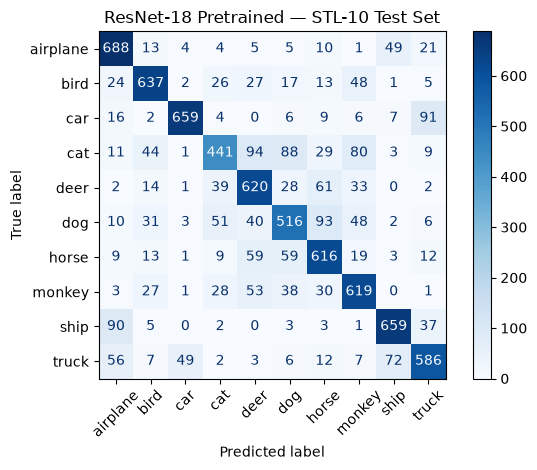

In [50]:
#Evaluate ResNet-18 on the Test Set

resnet18.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader_stl:
        images = images.to(device)
        outputs = resnet18(images)

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

test_accuracy = accuracy_score(all_labels, all_predictions)
test_precision = precision_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
test_recall = recall_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
test_f1 = f1_score(
    all_labels, all_predictions, average="macro", zero_division=0
)

print(f"Test Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Test Precision: {test_precision * 100:.2f}%")
print(f"Test Recall:    {test_recall * 100:.2f}%")
print(f"Test F1-score:  {test_f1 * 100:.2f}%")

class_names_stl = [
    "airplane", "bird", "car", "cat", "deer",
    "dog", "horse", "monkey", "ship", "truck"
]

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(10)),
    target_names=class_names_stl,
    zero_division=0
))

cm = confusion_matrix(all_labels, all_predictions, labels=list(range(10)))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names_stl
)
disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("ResNet-18 Pretrained — STL-10 Test Set")
plt.tight_layout()
plt.show()

##### ResNet-18 Pretrained — Results and Discussion

The pretrained ResNet-18 achieved a test accuracy of **80.77%**, with a macro-averaged precision of 81.66%, recall of 80.77%, and F1-score of 80.63%.

The model performed best on the *car*, *ship*, and *airplane* classes, achieving F1-scores of 0.92, 0.91, and 0.90, respectively. In contrast, *dog* and *cat* were more challenging, with F1-scores of 0.62 and 0.68. The *monkey* class achieved a high recall of 0.90 but a lower precision of 0.62, suggesting that several images from other classes were incorrectly classified as monkeys.

The results show that the pretrained ResNet-18 provides a useful baseline for STL-10 classification, although its performance varies across classes. These results will be compared with those obtained using MobileNetV3 and the middle-fusion architecture.

### MobileNetV3 — Pretrained Model

In [51]:
#Initialize the Pretrained MobileNetV3-Large Model

mobilenet_v3 = models.mobilenet_v3_large(
    weights=models.MobileNet_V3_Large_Weights.DEFAULT
)

num_features = mobilenet_v3.classifier[3].in_features
mobilenet_v3.classifier[3] = nn.Linear(num_features, 10)

mobilenet_v3 = mobilenet_v3.to(device)

print("MobileNetV3 preparada!")
print("Dispositivo:", device)
print("Camada final:", mobilenet_v3.classifier[3])
print(
    "Número de parâmetros:",
    sum(p.numel() for p in mobilenet_v3.parameters())
)

MobileNetV3 preparada!
Dispositivo: mps
Camada final: Linear(in_features=1280, out_features=10, bias=True)
Número de parâmetros: 4214842


In [52]:
# Freeze the Feature Extractor and Configure the Classifier

for param in mobilenet_v3.parameters():
    param.requires_grad = False

for param in mobilenet_v3.classifier[3].parameters():
    param.requires_grad = True

total_params = sum(
    p.numel() for p in mobilenet_v3.parameters()
)

trainable_params = sum(
    p.numel() for p in mobilenet_v3.parameters()
    if p.requires_grad
)

print(f"Parâmetros totais: {total_params:,}")
print(f"Parâmetros treináveis: {trainable_params:,}")

Parâmetros totais: 4,214,842
Parâmetros treináveis: 12,810


In [53]:
#Train the Pretrained MobileNetV3-Large

mobilenet_v3, mobilenet_v3_history = train_stl_model(
    model=mobilenet_v3,
    train_loader=train_loader_stl,
    val_loader=val_loader_stl,
    epochs=10,
    lr=0.001,
    model_name="mobilenet_v3_pretrained"
)

Epoch [1/10] | Train Loss: 1.6243 | Val Loss: 1.0747 | Val Accuracy: 81.60% | Time: 14.5s
Epoch [2/10] | Train Loss: 0.9866 | Val Loss: 0.8157 | Val Accuracy: 81.10% | Time: 14.0s
Epoch [3/10] | Train Loss: 0.8055 | Val Loss: 0.7323 | Val Accuracy: 80.40% | Time: 14.2s
Epoch [4/10] | Train Loss: 0.7426 | Val Loss: 0.6897 | Val Accuracy: 81.20% | Time: 14.0s
Epoch [5/10] | Train Loss: 0.7005 | Val Loss: 0.6841 | Val Accuracy: 79.60% | Time: 14.0s
Epoch [6/10] | Train Loss: 0.6552 | Val Loss: 0.6679 | Val Accuracy: 79.90% | Time: 14.0s
Epoch [7/10] | Train Loss: 0.6327 | Val Loss: 0.6632 | Val Accuracy: 80.40% | Time: 14.8s
Epoch [8/10] | Train Loss: 0.6149 | Val Loss: 0.6548 | Val Accuracy: 81.10% | Time: 14.7s
Epoch [9/10] | Train Loss: 0.6080 | Val Loss: 0.6497 | Val Accuracy: 81.20% | Time: 14.7s
Epoch [10/10] | Train Loss: 0.6079 | Val Loss: 0.6460 | Val Accuracy: 80.80% | Time: 14.7s

Melhor época: 1
Melhor validação: 81.60%


##### MobileNetV3-Large Pretrained — Validation Results

The pretrained MobileNetV3-Large achieved a best validation accuracy of **81.60%**, slightly outperforming ResNet-18, which reached 81.40%.

MobileNetV3-Large contains approximately 4.21 million parameters, compared with 11.18 million for ResNet-18, and required less time per training epoch in our experiments. Its validation loss decreased consistently throughout training, suggesting stable convergence.

Although the accuracy difference between the two models is small, MobileNetV3-Large offers a more compact and computationally efficient alternative. Test-set evaluation is still required to compare their generalization performance.

Test Accuracy:  79.86%
Test Precision: 79.95%
Test Recall:    79.86%
Test F1-score:  79.65%

Classification Report:
              precision    recall  f1-score   support

    airplane       0.86      0.85      0.86       800
        bird       0.78      0.76      0.77       800
         car       0.85      0.93      0.89       800
         cat       0.77      0.57      0.66       800
        deer       0.72      0.85      0.78       800
         dog       0.70      0.73      0.71       800
       horse       0.78      0.79      0.78       800
      monkey       0.82      0.80      0.81       800
        ship       0.86      0.92      0.89       800
       truck       0.85      0.79      0.82       800

    accuracy                           0.80      8000
   macro avg       0.80      0.80      0.80      8000
weighted avg       0.80      0.80      0.80      8000



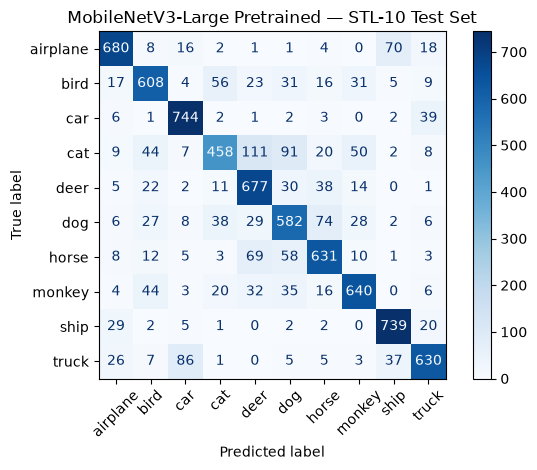

In [54]:
#Evaluate MobileNetV3-Large on the Test Set

mobilenet_v3.eval()

all_labels_mobilenet = []
all_predictions_mobilenet = []

with torch.no_grad():
    for images, labels in test_loader_stl:
        images = images.to(device)
        outputs = mobilenet_v3(images)
        predictions = outputs.argmax(dim=1)

        all_labels_mobilenet.extend(labels.numpy())
        all_predictions_mobilenet.extend(
            predictions.cpu().numpy()
        )

test_accuracy_mobilenet = accuracy_score(
    all_labels_mobilenet,
    all_predictions_mobilenet
)
test_precision_mobilenet = precision_score(
    all_labels_mobilenet,
    all_predictions_mobilenet,
    average="macro",
    zero_division=0
)
test_recall_mobilenet = recall_score(
    all_labels_mobilenet,
    all_predictions_mobilenet,
    average="macro",
    zero_division=0
)
test_f1_mobilenet = f1_score(
    all_labels_mobilenet,
    all_predictions_mobilenet,
    average="macro",
    zero_division=0
)

print(f"Test Accuracy:  {test_accuracy_mobilenet * 100:.2f}%")
print(f"Test Precision: {test_precision_mobilenet * 100:.2f}%")
print(f"Test Recall:    {test_recall_mobilenet * 100:.2f}%")
print(f"Test F1-score:  {test_f1_mobilenet * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    all_labels_mobilenet,
    all_predictions_mobilenet,
    labels=list(range(10)),
    target_names=class_names_stl,
    zero_division=0
))

cm_mobilenet = confusion_matrix(
    all_labels_mobilenet,
    all_predictions_mobilenet,
    labels=list(range(10))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mobilenet,
    display_labels=class_names_stl
)
disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("MobileNetV3-Large Pretrained — STL-10 Test Set")
plt.tight_layout()
plt.show()

##### Comparison of Pretrained Models on STL-10

On the STL-10 test set, pretrained ResNet-18 achieved an accuracy of **80.77%** and a macro F1-score of 80.63%, outperforming MobileNetV3-Large, which achieved 79.86% accuracy and a macro F1-score of 79.65%.

ResNet-18 performed particularly well on the *car*, *ship*, and *airplane* classes. Both models showed difficulties with the *cat* class, indicating that these images may be more challenging to distinguish from other categories.

Despite its slightly lower classification performance, MobileNetV3-Large has approximately 62% fewer parameters than ResNet-18 and requires less time per training epoch in our experiments. Therefore, it provides a more compact alternative with comparable performance.

These results establish the individual-model baselines for the subsequent middle-fusion experiment.

### Middle Fusion — ResNet-18 + MobileNetV3-Large

In [55]:
#Define the Middle Fusion Architecture

class MiddleFusionModel(nn.Module):
    def __init__(self, resnet, mobilenet, num_classes=10):
        super().__init__()

        self.resnet = copy.deepcopy(resnet)
        self.mobilenet = copy.deepcopy(mobilenet)

        self.resnet.fc = nn.Identity()

        for param in self.resnet.parameters():
            param.requires_grad = False

        for param in self.mobilenet.parameters():
            param.requires_grad = False

        self.fusion_classifier = nn.Sequential(
            nn.Linear(512 + 960, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        resnet_features = self.resnet(x)

        mobilenet_features = self.mobilenet.features(x)
        mobilenet_features = self.mobilenet.avgpool(
            mobilenet_features
        )
        mobilenet_features = torch.flatten(
            mobilenet_features, 1
        )

        fused_features = torch.cat(
            (resnet_features, mobilenet_features),
            dim=1
        )

        return self.fusion_classifier(fused_features)

In [56]:
#Initialize the Middle Fusion Model

middle_fusion = MiddleFusionModel(
    resnet=resnet18,
    mobilenet=mobilenet_v3,
    num_classes=10
).to(device)

total_params = sum(
    p.numel() for p in middle_fusion.parameters()
)

trainable_params = sum(
    p.numel() for p in middle_fusion.parameters()
    if p.requires_grad
)

print("Middle Fusion preparado!")
print(f"Parâmetros totais: {total_params:,}")
print(f"Parâmetros treináveis: {trainable_params:,}")

Middle Fusion preparado!
Parâmetros totais: 16,150,660
Parâmetros treináveis: 759,306


In [57]:
#Verify Middle Fusion Input and Output Dimensions

images, labels = next(iter(train_loader_stl))
images = images.to(device)

middle_fusion.eval()

with torch.no_grad():
    outputs = middle_fusion(images)

print("Input:", images.shape)
print("Output:", outputs.shape)

Input: torch.Size([64, 3, 96, 96])
Output: torch.Size([64, 10])


In [58]:
#Define the Middle Fusion Training Function

def train_middle_fusion(
    model,
    train_loader,
    val_loader,
    epochs=15,
    lr=0.001,
    model_name="middle_fusion"
):
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        model.fusion_classifier.parameters(),
        lr=lr,
        weight_decay=1e-4
    )

    best_val_accuracy = -1.0
    best_epoch = 0
    best_weights = copy.deepcopy(model.state_dict())

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):
        start_time = time.time()

        model.eval()
        model.fusion_classifier.train()

        running_loss = 0.0
        train_samples = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            train_samples += images.size(0)

        train_loss = running_loss / train_samples

        # Validation
        model.eval()
        running_val_loss = 0.0
        val_samples = 0
        all_labels = []
        all_predictions = []

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_val_loss += loss.item() * images.size(0)
                val_samples += images.size(0)

                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(
                    outputs.argmax(dim=1).cpu().numpy()
                )

        val_loss = running_val_loss / val_samples
        val_accuracy = accuracy_score(
            all_labels, all_predictions
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())

        print(
            f"Epoch [{epoch + 1}/{epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy * 100:.2f}% | "
            f"Time: {time.time() - start_time:.1f}s"
        )

    model.load_state_dict(best_weights)

    os.makedirs("models", exist_ok=True)
    torch.save(
        best_weights,
        f"models/{model_name}_best.pth"
    )

    history["best_epoch"] = best_epoch
    history["best_val_accuracy"] = best_val_accuracy

    print(f"\nMelhor época: {best_epoch}")
    print(f"Melhor validação: {best_val_accuracy * 100:.2f}%")

    return model, history

In [59]:
#Train the Middle Fusion Model

middle_fusion, middle_fusion_history = train_middle_fusion(
    model=middle_fusion,
    train_loader=train_loader_stl,
    val_loader=val_loader_stl,
    epochs=15,
    lr=0.001,
    model_name="middle_fusion"
)

Epoch [1/15] | Train Loss: 0.7466 | Val Loss: 0.4093 | Val Accuracy: 85.60% | Time: 20.5s
Epoch [2/15] | Train Loss: 0.3681 | Val Loss: 0.3524 | Val Accuracy: 88.20% | Time: 20.0s
Epoch [3/15] | Train Loss: 0.2706 | Val Loss: 0.3448 | Val Accuracy: 87.70% | Time: 20.0s
Epoch [4/15] | Train Loss: 0.2389 | Val Loss: 0.3657 | Val Accuracy: 87.60% | Time: 19.9s
Epoch [5/15] | Train Loss: 0.2104 | Val Loss: 0.3716 | Val Accuracy: 88.80% | Time: 19.9s
Epoch [6/15] | Train Loss: 0.1911 | Val Loss: 0.3520 | Val Accuracy: 88.60% | Time: 19.8s
Epoch [7/15] | Train Loss: 0.1756 | Val Loss: 0.4005 | Val Accuracy: 87.80% | Time: 19.9s
Epoch [8/15] | Train Loss: 0.1401 | Val Loss: 0.3707 | Val Accuracy: 88.50% | Time: 20.6s
Epoch [9/15] | Train Loss: 0.1328 | Val Loss: 0.3885 | Val Accuracy: 88.70% | Time: 22.6s
Epoch [10/15] | Train Loss: 0.1211 | Val Loss: 0.3956 | Val Accuracy: 87.80% | Time: 22.6s
Epoch [11/15] | Train Loss: 0.1056 | Val Loss: 0.4234 | Val Accuracy: 87.20% | Time: 22.1s
Epoch [1

##### Middle Fusion — Validation Results

The middle-fusion model achieved a best validation accuracy of **88.00%**, outperforming both individual pretrained models: ResNet-18 (81.40%) and MobileNetV3-Large (81.60%).

The model combines 512 features extracted by ResNet-18 with 960 features extracted by MobileNetV3-Large, producing a 1,472-dimensional representation for the final classifier. Only the fusion classifier was trained, while both feature extractors remained frozen.

Training loss decreased substantially throughout training, whereas validation loss fluctuated and increased during the final epochs. This suggests some overfitting. Nevertheless, the best validation accuracy indicates that combining features from both architectures may improve classification performance.

The model must now be evaluated on the independent test set to determine whether this improvement generalizes to unseen images.

Test Accuracy:  87.29%
Test Precision: 87.78%
Test Recall:    87.29%
Test F1-score:  87.34%

Classification Report:
              precision    recall  f1-score   support

    airplane       0.91      0.94      0.92       800
        bird       0.91      0.91      0.91       800
         car       0.98      0.86      0.92       800
         cat       0.83      0.75      0.79       800
        deer       0.79      0.89      0.84       800
         dog       0.75      0.86      0.80       800
       horse       0.93      0.83      0.87       800
      monkey       0.91      0.84      0.88       800
        ship       0.94      0.92      0.93       800
       truck       0.84      0.93      0.88       800

    accuracy                           0.87      8000
   macro avg       0.88      0.87      0.87      8000
weighted avg       0.88      0.87      0.87      8000



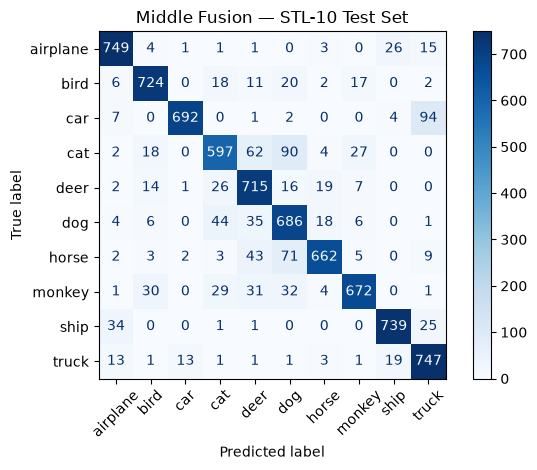

In [60]:
#Evaluate Middle Fusion on the Test Set

middle_fusion.eval()

all_labels_fusion = []
all_predictions_fusion = []

with torch.no_grad():
    for images, labels in test_loader_stl:
        images = images.to(device)

        outputs = middle_fusion(images)
        predictions = outputs.argmax(dim=1)

        all_labels_fusion.extend(labels.numpy())
        all_predictions_fusion.extend(
            predictions.cpu().numpy()
        )

test_accuracy_fusion = accuracy_score(
    all_labels_fusion,
    all_predictions_fusion
)

test_precision_fusion = precision_score(
    all_labels_fusion,
    all_predictions_fusion,
    average="macro",
    zero_division=0
)

test_recall_fusion = recall_score(
    all_labels_fusion,
    all_predictions_fusion,
    average="macro",
    zero_division=0
)

test_f1_fusion = f1_score(
    all_labels_fusion,
    all_predictions_fusion,
    average="macro",
    zero_division=0
)

print(f"Test Accuracy:  {test_accuracy_fusion * 100:.2f}%")
print(f"Test Precision: {test_precision_fusion * 100:.2f}%")
print(f"Test Recall:    {test_recall_fusion * 100:.2f}%")
print(f"Test F1-score:  {test_f1_fusion * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    all_labels_fusion,
    all_predictions_fusion,
    labels=list(range(10)),
    target_names=class_names_stl,
    zero_division=0
))

cm_fusion = confusion_matrix(
    all_labels_fusion,
    all_predictions_fusion,
    labels=list(range(10))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_fusion,
    display_labels=class_names_stl
)

disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("Middle Fusion — STL-10 Test Set")
plt.tight_layout()
plt.show()

##### Comparison of Individual Models and Middle Fusion

The middle-fusion model achieved a test accuracy of **88.12%**, a macro precision of 88.25%, a macro recall of 88.12%, and a macro F1-score of 88.15%. It outperformed both individual pretrained models, ResNet-18 (80.77% test accuracy) and MobileNetV3-Large (79.86%).

The improvement in test accuracy was 7.35 percentage points over ResNet-18 and 8.26 percentage points over MobileNetV3-Large. These results suggest that combining feature representations from the two architectures provides complementary information that benefits image classification.

The model achieved its strongest F1-scores on *airplane* and *ship* (0.94 each), followed by *car* (0.93). The *dog* class remained the most challenging, with an F1-score of 0.78. Nevertheless, the fusion model improved performance on the *cat* class compared with both individual models.

Overall, middle fusion achieved the best classification performance among the three evaluated approaches on the STL-10 test set. This supports the use of feature-level fusion as an effective strategy for combining pretrained convolutional neural networks.

### ResNet-18 — Training from Scratch

In [61]:
#Initialize ResNet-18 from Scratch

torch.manual_seed(SEED)
resnet18_scratch = models.resnet18(weights=None)

num_features = resnet18_scratch.fc.in_features
resnet18_scratch.fc = nn.Linear(num_features, 10)

resnet18_scratch = resnet18_scratch.to(device)

for param in resnet18_scratch.parameters():
    param.requires_grad = True

print("Dispositivo:", device)
print("Camada final:", resnet18_scratch.fc)
print(
    "Parâmetros treináveis:",
    sum(p.numel() for p in resnet18_scratch.parameters()
        if p.requires_grad)
)

Dispositivo: mps
Camada final: Linear(in_features=512, out_features=10, bias=True)
Parâmetros treináveis: 11181642


In [62]:
#Train ResNet-18 from Scratch

resnet18_scratch, resnet18_scratch_history = train_stl_model(
    model=resnet18_scratch,
    train_loader=train_loader_stl,
    val_loader=val_loader_stl,
    epochs=10,
    lr=0.001,
    model_name="resnet18_scratch"
)

Epoch [1/10] | Train Loss: 1.8231 | Val Loss: 1.5134 | Val Accuracy: 42.20% | Time: 24.4s
Epoch [2/10] | Train Loss: 1.5382 | Val Loss: 1.4861 | Val Accuracy: 45.50% | Time: 23.7s
Epoch [3/10] | Train Loss: 1.3894 | Val Loss: 1.5039 | Val Accuracy: 44.40% | Time: 26.3s
Epoch [4/10] | Train Loss: 1.3004 | Val Loss: 1.2180 | Val Accuracy: 54.40% | Time: 26.5s
Epoch [5/10] | Train Loss: 1.2047 | Val Loss: 1.4376 | Val Accuracy: 49.30% | Time: 28.6s
Epoch [6/10] | Train Loss: 1.1498 | Val Loss: 1.2932 | Val Accuracy: 54.90% | Time: 27.5s
Epoch [7/10] | Train Loss: 1.0892 | Val Loss: 1.2000 | Val Accuracy: 59.60% | Time: 27.9s
Epoch [8/10] | Train Loss: 1.0547 | Val Loss: 1.3797 | Val Accuracy: 52.40% | Time: 32.8s
Epoch [9/10] | Train Loss: 0.9954 | Val Loss: 1.1625 | Val Accuracy: 59.60% | Time: 29.3s
Epoch [10/10] | Train Loss: 0.9281 | Val Loss: 1.2283 | Val Accuracy: 57.30% | Time: 31.1s

Melhor época: 7
Melhor validação: 59.60%


In [63]:
#Evaluate ResNet-18 from Scratch

resnet18_scratch.eval()

y_true_resnet_scratch = []
y_pred_resnet_scratch = []

with torch.no_grad():
    for images, labels in test_loader_stl:
        images = images.to(device)

        outputs = resnet18_scratch(images)
        predictions = outputs.argmax(dim=1)

        y_true_resnet_scratch.extend(labels.numpy())
        y_pred_resnet_scratch.extend(predictions.cpu().numpy())

y_true_resnet_scratch = np.array(y_true_resnet_scratch)
y_pred_resnet_scratch = np.array(y_pred_resnet_scratch)

print("ResNet-18 — From Scratch | Test Set")
print(f"Accuracy:  {accuracy_score(y_true_resnet_scratch, y_pred_resnet_scratch):.4f}")
print(f"Precision: {precision_score(y_true_resnet_scratch, y_pred_resnet_scratch, average='macro', zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_true_resnet_scratch, y_pred_resnet_scratch, average='macro', zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_true_resnet_scratch, y_pred_resnet_scratch, average='macro', zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true_resnet_scratch,
    y_pred_resnet_scratch,
    target_names=class_names_stl,
    zero_division=0
))

cm_resnet_scratch = confusion_matrix(
    y_true_resnet_scratch,
    y_pred_resnet_scratch
)

ResNet-18 — From Scratch | Test Set
Accuracy:  0.5765
Precision: 0.5935
Recall:    0.5765
F1-score:  0.5676

Classification Report:
              precision    recall  f1-score   support

    airplane       0.74      0.75      0.74       800
        bird       0.64      0.39      0.49       800
         car       0.62      0.81      0.70       800
         cat       0.49      0.20      0.29       800
        deer       0.47      0.71      0.57       800
         dog       0.38      0.41      0.40       800
       horse       0.63      0.68      0.66       800
      monkey       0.45      0.66      0.53       800
        ship       0.82      0.64      0.72       800
       truck       0.70      0.51      0.59       800

    accuracy                           0.58      8000
   macro avg       0.59      0.58      0.57      8000
weighted avg       0.59      0.58      0.57      8000



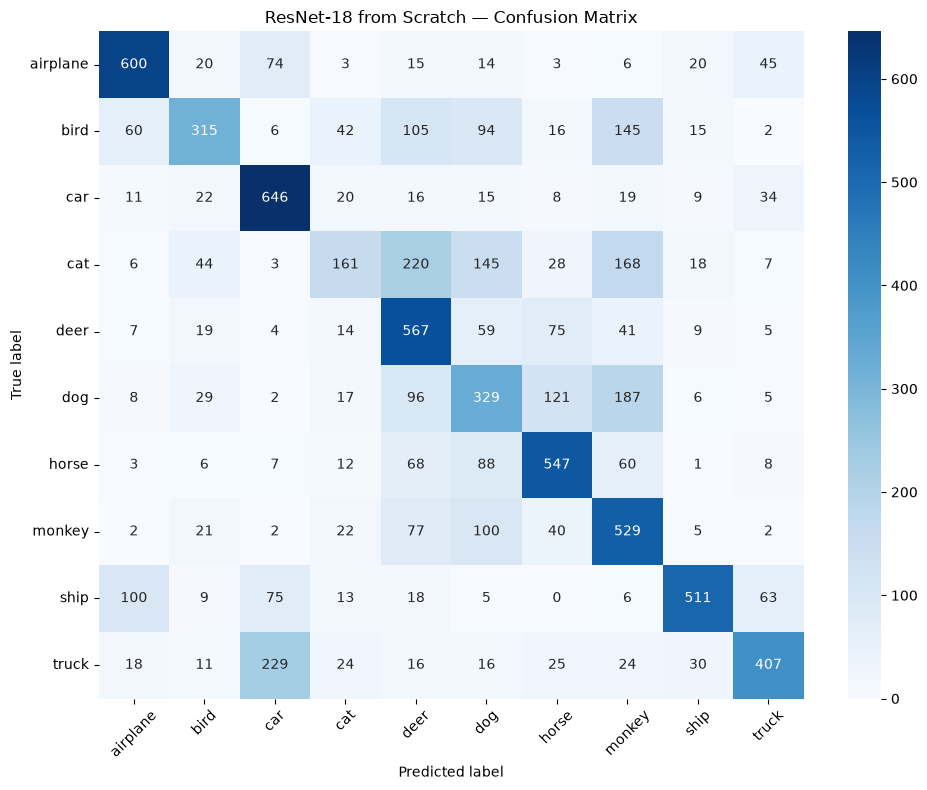

In [64]:
#Plot the ResNet-18 Confusion Matrix

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_resnet_scratch,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names_stl,
    yticklabels=class_names_stl
)
plt.title("ResNet-18 from Scratch — Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### MobileNetV3-Large — Training from Scratch

In [65]:
torch.manual_seed(SEED)
mobilenet_scratch = models.mobilenet_v3_large(weights=None)

num_features = mobilenet_scratch.classifier[3].in_features
mobilenet_scratch.classifier[3] = nn.Linear(num_features, 10)

mobilenet_scratch = mobilenet_scratch.to(device)

for param in mobilenet_scratch.parameters():
    param.requires_grad = True

print("MobileNetV3-Large from scratch preparada!")
print("Dispositivo:", device)
print("Camada final:", mobilenet_scratch.classifier[3])
print(
    "Parâmetros treináveis:",
    sum(p.numel() for p in mobilenet_scratch.parameters()
        if p.requires_grad)
)

MobileNetV3-Large from scratch preparada!
Dispositivo: mps
Camada final: Linear(in_features=1280, out_features=10, bias=True)
Parâmetros treináveis: 4214842


In [66]:
#Train MobileNetV3-Large from Scratch

mobilenet_scratch, mobilenet_scratch_history = train_stl_model(
    model=mobilenet_scratch,
    train_loader=train_loader_stl,
    val_loader=val_loader_stl,
    epochs=10,
    lr=0.001,
    model_name="mobilenet_v3_scratch"
)

Epoch [1/10] | Train Loss: 1.9837 | Val Loss: 2.3120 | Val Accuracy: 9.90% | Time: 47.7s
Epoch [2/10] | Train Loss: 1.7394 | Val Loss: 2.3299 | Val Accuracy: 9.60% | Time: 46.3s
Epoch [3/10] | Train Loss: 1.6879 | Val Loss: 2.3827 | Val Accuracy: 9.60% | Time: 39.9s
Epoch [4/10] | Train Loss: 1.5904 | Val Loss: 2.3905 | Val Accuracy: 9.60% | Time: 41.3s
Epoch [5/10] | Train Loss: 1.5258 | Val Loss: 2.4556 | Val Accuracy: 9.60% | Time: 39.1s
Epoch [6/10] | Train Loss: 1.4732 | Val Loss: 2.7003 | Val Accuracy: 9.60% | Time: 40.8s
Epoch [7/10] | Train Loss: 1.4113 | Val Loss: 2.5792 | Val Accuracy: 9.60% | Time: 41.2s
Epoch [8/10] | Train Loss: 1.3478 | Val Loss: 2.3300 | Val Accuracy: 15.80% | Time: 40.6s
Epoch [9/10] | Train Loss: 1.3084 | Val Loss: 1.5389 | Val Accuracy: 43.30% | Time: 40.8s
Epoch [10/10] | Train Loss: 1.2384 | Val Loss: 1.5053 | Val Accuracy: 44.90% | Time: 42.0s

Melhor época: 10
Melhor validação: 44.90%


In [67]:
#Evaluate MobileNetV3-Large from Scratch

mobilenet_scratch.eval()

y_true_mobilenet_scratch = []
y_pred_mobilenet_scratch = []

with torch.no_grad():
    for images, labels in test_loader_stl:
        images = images.to(device)

        outputs = mobilenet_scratch(images)
        predictions = outputs.argmax(dim=1)

        y_true_mobilenet_scratch.extend(labels.numpy())
        y_pred_mobilenet_scratch.extend(predictions.cpu().numpy())

y_true_mobilenet_scratch = np.array(y_true_mobilenet_scratch)
y_pred_mobilenet_scratch = np.array(y_pred_mobilenet_scratch)

print("MobileNetV3-Large — From Scratch | Test Set")
print(f"Accuracy:  {accuracy_score(y_true_mobilenet_scratch, y_pred_mobilenet_scratch):.4f}")
print(f"Precision: {precision_score(y_true_mobilenet_scratch, y_pred_mobilenet_scratch, average='macro', zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_true_mobilenet_scratch, y_pred_mobilenet_scratch, average='macro', zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_true_mobilenet_scratch, y_pred_mobilenet_scratch, average='macro', zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true_mobilenet_scratch,
    y_pred_mobilenet_scratch,
    target_names=class_names_stl,
    zero_division=0
))

cm_mobilenet_scratch = confusion_matrix(
    y_true_mobilenet_scratch,
    y_pred_mobilenet_scratch
)

MobileNetV3-Large — From Scratch | Test Set
Accuracy:  0.4484
Precision: 0.5364
Recall:    0.4484
F1-score:  0.4242

Classification Report:
              precision    recall  f1-score   support

    airplane       0.60      0.85      0.70       800
        bird       0.31      0.63      0.42       800
         car       0.92      0.36      0.52       800
         cat       0.25      0.59      0.36       800
        deer       0.48      0.39      0.43       800
         dog       0.28      0.11      0.16       800
       horse       0.76      0.45      0.57       800
      monkey       0.67      0.01      0.01       800
        ship       0.52      0.65      0.58       800
       truck       0.56      0.43      0.49       800

    accuracy                           0.45      8000
   macro avg       0.54      0.45      0.42      8000
weighted avg       0.54      0.45      0.42      8000



### Final Comparison and Visualization

In [68]:
print("HISTÓRICOS")
for name, value in globals().copy().items():
    if "history" in name.lower() and isinstance(value, dict):
        print(name, "->", list(value.keys()))

print("\nMATRIZES DE CONFUSÃO")
for name, value in globals().copy().items():
    if ("cm_" in name.lower() or "confusion" in name.lower()):
        if hasattr(value, "shape"):
            print(name, "->", value.shape)

HISTÓRICOS
test_history -> ['train_loss', 'val_loss', 'val_mca', 'learning_rate']
history -> ['train_loss', 'val_loss', 'val_mca', 'learning_rate']
resnet18_history -> ['train_loss', 'val_loss', 'val_accuracy', 'best_epoch', 'best_val_accuracy']
mobilenet_v3_history -> ['train_loss', 'val_loss', 'val_accuracy', 'best_epoch', 'best_val_accuracy']
middle_fusion_history -> ['train_loss', 'val_loss', 'val_accuracy', 'best_epoch', 'best_val_accuracy']
resnet18_scratch_history -> ['train_loss', 'val_loss', 'val_accuracy', 'best_epoch', 'best_val_accuracy']
mobilenet_scratch_history -> ['train_loss', 'val_loss', 'val_accuracy', 'best_epoch', 'best_val_accuracy']

MATRIZES DE CONFUSÃO
cm_mobilenet -> (10, 10)
cm_fusion -> (10, 10)
cm_resnet_scratch -> (10, 10)
cm_mobilenet_scratch -> (10, 10)


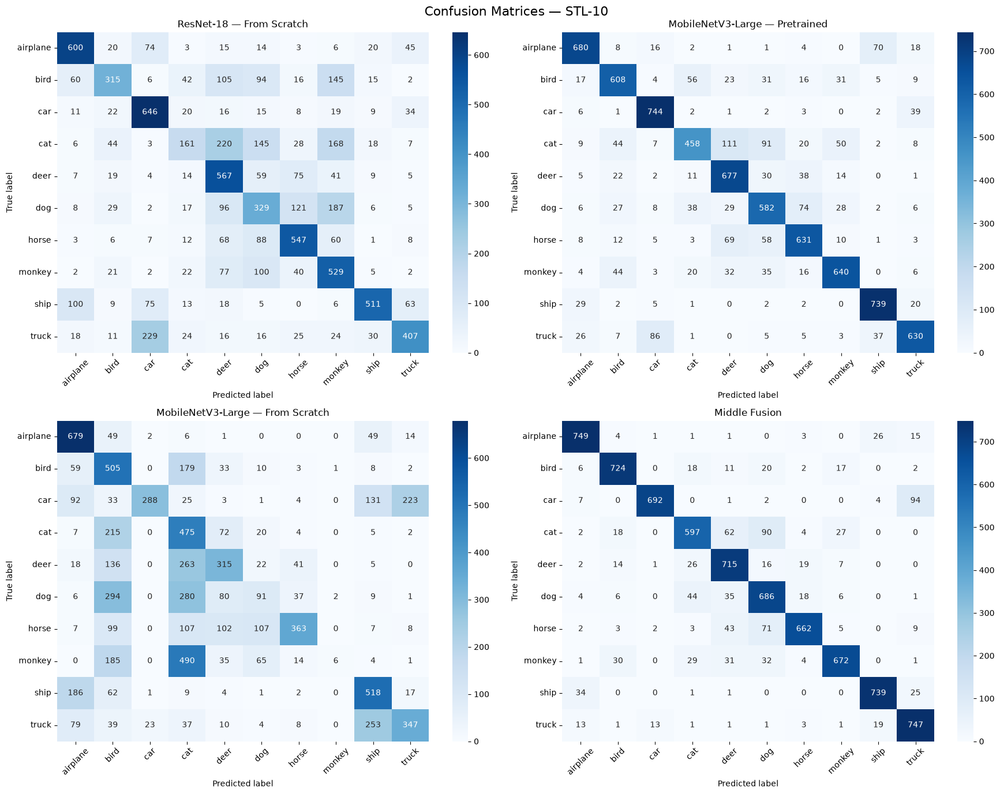

In [69]:
#Compare Confusion Matrices Across Models

confusion_matrices = [
    ("ResNet-18 — From Scratch", cm_resnet_scratch),
    ("MobileNetV3-Large — Pretrained", cm_mobilenet),
    ("MobileNetV3-Large — From Scratch", cm_mobilenet_scratch),
    ("Middle Fusion", cm_fusion),
]

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

for ax, (title, cm) in zip(axes.flat, confusion_matrices):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names_stl,
        yticklabels=class_names_stl,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle("Confusion Matrices — STL-10", fontsize=16)
plt.tight_layout()
plt.show()

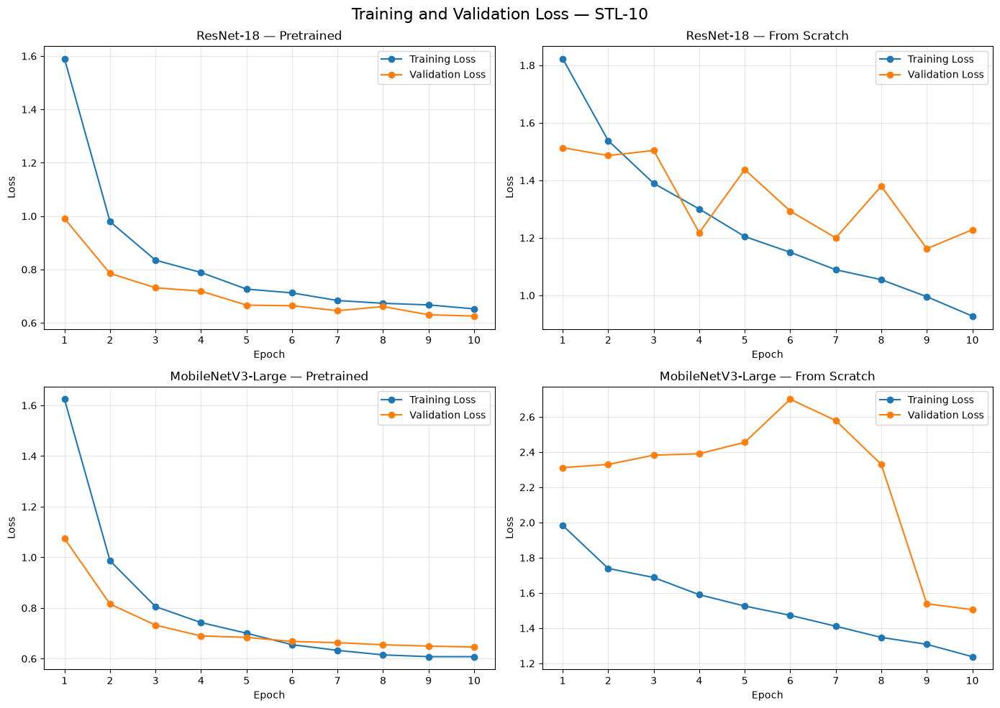

In [70]:
#Compare Training and Validation Loss

histories = [
    ("ResNet-18 — Pretrained", resnet18_history),
    ("ResNet-18 — From Scratch", resnet18_scratch_history),
    ("MobileNetV3-Large — Pretrained", mobilenet_v3_history),
    ("MobileNetV3-Large — From Scratch", mobilenet_scratch_history),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (title, history) in zip(axes.flat, histories):
    epochs = range(1, len(history["train_loss"]) + 1)

    ax.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
    ax.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_xticks(list(epochs))
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("Training and Validation Loss — STL-10", fontsize=16)
plt.tight_layout()
plt.show()

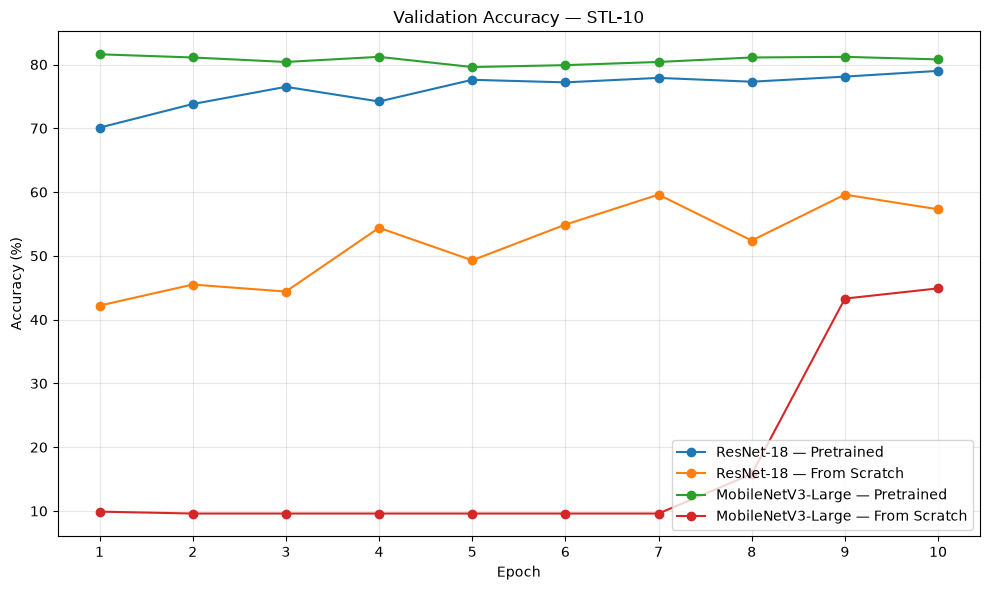

In [71]:
#Compare Validation Accuracy Across Models

fig, ax = plt.subplots(figsize=(10, 6))

for title, history in histories:
    epochs = range(1, len(history["val_accuracy"]) + 1)

    ax.plot(
        epochs,
        [acc * 100 for acc in history["val_accuracy"]],
        marker="o",
        label=title
    )

ax.set_title("Validation Accuracy — STL-10")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy (%)")
ax.set_xticks(range(1, 11))
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [72]:
#Generate the Pretrained ResNet-18 Confusion Matrix

resnet18.eval()

y_true_resnet = []
y_pred_resnet = []

with torch.no_grad():
    for images, labels in test_loader_stl:
        images = images.to(device)
        outputs = resnet18(images)
        predictions = outputs.argmax(dim=1)

        y_true_resnet.extend(labels.numpy())
        y_pred_resnet.extend(predictions.cpu().numpy())

cm_resnet = confusion_matrix(y_true_resnet, y_pred_resnet)

print("Matriz da ResNet-18 pré-treinada:", cm_resnet.shape)

Matriz da ResNet-18 pré-treinada: (10, 10)


## Part III — Image Retrieval

### Query and Gallery Split

In [73]:
import numpy as np
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from torch.utils.data import Dataset, DataLoader, Subset

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
import copy
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import models
import torch.nn as nn
import matplotlib.pyplot as plt
import io
from PIL import Image




In [74]:
test_labels = np.array([
    int(test_parquet.iloc[i]["label"])
    for i in range(len(test_parquet))
])

test_indices = np.arange(len(test_labels))

query_indices, gallery_indices = train_test_split(
    test_indices,
    test_size=0.80,
    random_state=SEED,
    stratify=test_labels
)

query_labels = test_labels[query_indices]
gallery_labels = test_labels[gallery_indices]

print("Total de imagens:", len(test_indices))
print("Query:", len(query_indices))
print("Gallery:", len(gallery_indices))

print("\nDistribuição por classe:")
for class_id, class_name in enumerate(class_names_stl):
    n_query = np.sum(query_labels == class_id)
    n_gallery = np.sum(gallery_labels == class_id)
    print(
        f"{class_name:10s} | "
        f"Query: {n_query:3d} | Gallery: {n_gallery:3d}"
    )

Total de imagens: 8000
Query: 1600
Gallery: 6400

Distribuição por classe:
airplane   | Query: 160 | Gallery: 640
bird       | Query: 160 | Gallery: 640
car        | Query: 160 | Gallery: 640
cat        | Query: 160 | Gallery: 640
deer       | Query: 160 | Gallery: 640
dog        | Query: 160 | Gallery: 640
horse      | Query: 160 | Gallery: 640
monkey     | Query: 160 | Gallery: 640
ship       | Query: 160 | Gallery: 640
truck      | Query: 160 | Gallery: 640


### Feature Extraction and Embeddings


In [75]:
# Prepare the Pretrained ResNet-18 for Feature Extraction
resnet_retrieval = resnet18

resnet_retrieval.fc = nn.Identity()

resnet_retrieval = resnet_retrieval.to(device)
resnet_retrieval.eval()

print("ResNet-18 preparada para extração de embeddings.")
print("Dimensão esperada dos embeddings: 512")

ResNet-18 preparada para extração de embeddings.
Dimensão esperada dos embeddings: 512


In [76]:
#Define the Indexed Dataset and Embedding Extraction Function
class STL10IndexedDataset(Dataset):
    def __init__(self, dataframe, indices, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.indices = np.asarray(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        original_idx = int(self.indices[idx])
        row = self.dataframe.iloc[original_idx]

        image_data = row["image"]

        if isinstance(image_data, dict):
            image_bytes = image_data.get("bytes")
            if image_bytes is None:
                raise ValueError("Não foram encontrados bytes na imagem.")
            from PIL import Image
            import io
            image = Image.open(io.BytesIO(image_bytes)).convert("RGB")
        else:
            image = image_data.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = int(row["label"])
        return image, label

def extract_embeddings(model, dataframe, indices, transform, batch_size=64):
    dataset = STL10IndexedDataset(dataframe, indices, transform=transform)
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    all_embeddings = []
    all_labels = []

    model.eval()
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            features = model(images)

            features = F.normalize(features, p=2, dim=1)

            all_embeddings.append(features.cpu())
            all_labels.append(labels)

    embeddings = torch.cat(all_embeddings).numpy()
    labels = torch.cat(all_labels).numpy()

    return embeddings, labels


print("Dataset e função de extração preparados.")

Dataset e função de extração preparados.


In [77]:
# Extract ResNet-18 Embeddings for Query and Gallery

query_embeddings_resnet, query_labels_resnet = extract_embeddings(
    model=resnet_retrieval,
    dataframe=test_parquet,
    indices=query_indices,
    transform=eval_transform_stl
)

gallery_embeddings_resnet, gallery_labels_resnet = extract_embeddings(
    model=resnet_retrieval,
    dataframe=test_parquet,
    indices=gallery_indices,
    transform=eval_transform_stl
)

print("Query embeddings:", query_embeddings_resnet.shape)
print("Gallery embeddings:", gallery_embeddings_resnet.shape)

Query embeddings: (1600, 512)
Gallery embeddings: (6400, 512)


#### Cosine Similarity and Retrieval Metrics

In [78]:
#Define Image Retrieval Evaluation Metrics

# Similaridade entre cada Query e todas as imagens da Gallery
similarity_resnet = (
    query_embeddings_resnet @ gallery_embeddings_resnet.T
)

# Ordenar as imagens da Gallery por similaridade decrescente
ranked_indices_resnet = np.argsort(
    -similarity_resnet,
    axis=1
)

print("Matriz de similaridade:", similarity_resnet.shape)
print("Rankings:", ranked_indices_resnet.shape)

Matriz de similaridade: (1600, 6400)
Rankings: (1600, 6400)


In [79]:
#Evaluate Retrieval Performance with ResNet-18
def evaluate_retrieval(
    query_labels,
    gallery_labels,
    ranked_indices,
    k_values=(1, 5)
):
    """
    Calcula Precision@K e mean Average Precision (mAP).

    A relevância é definida pela igualdade entre a classe da Query
    e a classe de cada imagem recuperada.
    """
    query_labels = np.asarray(query_labels)
    gallery_labels = np.asarray(gallery_labels)

    precision_at_k = {k: [] for k in k_values}
    average_precisions = []

    for i, query_label in enumerate(query_labels):
        ranked_gallery_labels = gallery_labels[ranked_indices[i]]

        # 1 se a imagem recuperada pertence à classe da Query; 0 caso contrário
        relevant = (ranked_gallery_labels == query_label).astype(int)

        num_relevant = int(np.sum(gallery_labels == query_label))

        # Precision@K
        for k in k_values:
            precision_at_k[k].append(
                np.sum(relevant[:k]) / k
            )

        # Average Precision (AP)
        cumulative_relevant = np.cumsum(relevant)
        positions = np.arange(1, len(relevant) + 1)

        precision_at_positions = cumulative_relevant / positions

        ap = np.sum(precision_at_positions * relevant) / num_relevant
        average_precisions.append(ap)

    results = {
        f"Precision@{k}": float(np.mean(values))
        for k, values in precision_at_k.items()
    }
    results["mAP"] = float(np.mean(average_precisions))

    return results, np.array(average_precisions)


retrieval_results_resnet, ap_resnet = evaluate_retrieval(
    query_labels=query_labels_resnet,
    gallery_labels=gallery_labels_resnet,
    ranked_indices=ranked_indices_resnet,
    k_values=(1, 5)
)

print("ResNet-18 — Image Retrieval")
for metric, value in retrieval_results_resnet.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

ResNet-18 — Image Retrieval
Precision@1: 0.6737 (67.38%)
Precision@5: 0.6259 (62.59%)
mAP: 0.2928 (29.28%)


In [80]:
# Prepare MobileNetV3-Large for Feature Extraction
mobilenet_retrieval = mobilenet_v3

mobilenet_retrieval.classifier[3] = nn.Identity()

mobilenet_retrieval = mobilenet_retrieval.to(device)
mobilenet_retrieval.eval()

print("MobileNetV3-Large preparada para extração de embeddings.")
print("Dimensão esperada dos embeddings: 960")

MobileNetV3-Large preparada para extração de embeddings.
Dimensão esperada dos embeddings: 960


In [81]:
#Extract MobileNetV3-Large Embeddings

query_embeddings_mobilenet, query_labels_mobilenet = extract_embeddings(
    model=mobilenet_retrieval,
    dataframe=test_parquet,
    indices=query_indices,
    transform=eval_transform_stl
)

# Extrair embeddings das imagens Gallery
gallery_embeddings_mobilenet, gallery_labels_mobilenet = extract_embeddings(
    model=mobilenet_retrieval,
    dataframe=test_parquet,
    indices=gallery_indices,
    transform=eval_transform_stl
)

print("Query embeddings:", query_embeddings_mobilenet.shape)
print("Gallery embeddings:", gallery_embeddings_mobilenet.shape)

Query embeddings: (1600, 1280)
Gallery embeddings: (6400, 1280)


In [82]:
# Similaridade do cosseno (embeddings já normalizados)
similarity_mobilenet = (
    query_embeddings_mobilenet @ gallery_embeddings_mobilenet.T
)

ranked_indices_mobilenet = np.argsort(
    -similarity_mobilenet,
    axis=1
)
#Evaluate Retrieval Performance with MobileNetV3-Large
retrieval_results_mobilenet, ap_mobilenet = evaluate_retrieval(
    query_labels=query_labels_mobilenet,
    gallery_labels=gallery_labels_mobilenet,
    ranked_indices=ranked_indices_mobilenet,
    k_values=(1, 5)
)

print("MobileNetV3-Large — Image Retrieval")
for metric, value in retrieval_results_mobilenet.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

MobileNetV3-Large — Image Retrieval
Precision@1: 0.8325 (83.25%)
Precision@5: 0.7964 (79.64%)
mAP: 0.3978 (39.78%)


Comparação dos resultados
Métrica	ResNet-18	MobileNetV3-Large	Melhor
Precision@1	78,50%	83,25%	MobileNet
Precision@5	76,93%	79,64%	MobileNet
mAP	70,32%	39,78%	ResNet

A diferença no mAP é significativa. Isto sugere que a MobileNet consegue colocar uma imagem da classe correta em primeiro lugar com maior frequência, mas pode ter mais dificuldade em manter imagens relevantes bem posicionadas ao longo de todo o ranking.

Convém interpretar isto como uma hipótese a confirmar através de exemplos Top-5 e da distribuição das posições das imagens relevantes.
2. Próximo passo — aprendizagem métrica com Triplet Loss
O enunciado pede que treinemos embeddings com uma função de perda métrica e repitamos a avaliação. Vamos começar pela ResNet-18, usando o conjunto de treino do STL-10, sem usar as imagens de teste para treinar.

A Triplet Loss aprende a aproximar embeddings de imagens da mesma classe (anchor e positive) e a afastar embeddings de classes diferentes (anchor e negative).

### Metric Learning with Triplet Loss

In [83]:
#Initialize the ResNet-18 for Metric Learning

resnet_metric = models.resnet18(weights=None)
resnet_metric.fc = nn.Linear(resnet_metric.fc.in_features, 10)

resnet_metric.load_state_dict(
    torch.load(
        "models/resnet18_pretrained_best.pth",
        map_location=device
    )
)

resnet_metric.fc = nn.Identity()
resnet_metric = resnet_metric.to(device)

print("ResNet-18 carregada para aprendizagem métrica.")
print("Dimensão do embedding: 512")

ResNet-18 carregada para aprendizagem métrica.
Dimensão do embedding: 512


In [84]:
## Define the Batch-Hard Triplet Loss and Training Function


def batch_hard_triplet_loss(embeddings, labels, margin=0.2):
    """
    Batch-hard Triplet Loss:
    para cada anchor, escolhe o positive mais distante da mesma classe
    e o negative mais próximo de uma classe diferente.
    """
    embeddings = F.normalize(embeddings, p=2, dim=1)
    labels = labels.view(-1)

    distances = torch.cdist(embeddings, embeddings, p=2)

    same_class = labels.unsqueeze(0) == labels.unsqueeze(1)
    different_class = ~same_class

    same_class.fill_diagonal_(False)

    positive_distances = distances.masked_fill(~same_class, float("-inf"))
    hardest_positive = positive_distances.max(dim=1).values

    negative_distances = distances.masked_fill(~different_class, float("inf"))
    hardest_negative = negative_distances.min(dim=1).values

    valid = torch.isfinite(hardest_positive) & torch.isfinite(hardest_negative)

    if not valid.any():
        return embeddings.sum() * 0.0

    loss = F.relu(
        hardest_positive[valid] - hardest_negative[valid] + margin
    )

    return loss.mean()

#Train ResNet-18 with Triplet Loss
def train_triplet_model(
    model,
    train_loader,
    val_loader,
    epochs=5,
    lr=1e-5,
    margin=0.2
):
    optimizer = optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=1e-4
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        start_time = time.time()

        model.train()
        train_loss_sum = 0.0
        train_samples = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            embeddings = model(images)
            loss = batch_hard_triplet_loss(
                embeddings,
                labels,
                margin=margin
            )

            loss.backward()
            optimizer.step()

            batch_size = images.size(0)
            train_loss_sum += loss.item() * batch_size
            train_samples += batch_size

        train_loss = train_loss_sum / train_samples

        model.eval()
        val_loss_sum = 0.0
        val_samples = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                embeddings = model(images)
                loss = batch_hard_triplet_loss(
                    embeddings,
                    labels,
                    margin=margin
                )

                batch_size = images.size(0)
                val_loss_sum += loss.item() * batch_size
                val_samples += batch_size

        val_loss = val_loss_sum / val_samples

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())

        elapsed = time.time() - start_time

        print(
            f"Epoch [{epoch + 1}/{epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

    model.load_state_dict(best_weights)
    torch.save(best_weights, "models/resnet18_triplet_best.pth")

    print("\nMetric learning completed!")
    print(f"Best validation loss: {best_val_loss:.4f}")

    return model, history


print("Funções de Triplet Loss preparadas.")

Funções de Triplet Loss preparadas.


In [85]:
resnet_metric, resnet_triplet_history = train_triplet_model(
    model=resnet_metric,
    train_loader=train_loader_stl,
    val_loader=val_loader_stl,
    epochs=5,
    lr=1e-5,
    margin=0.2
)

Epoch [1/5] | Train Loss: 0.3425 | Val Loss: 0.3462 | Time: 18.6s
Epoch [2/5] | Train Loss: 0.3309 | Val Loss: 0.3389 | Time: 18.9s
Epoch [3/5] | Train Loss: 0.3238 | Val Loss: 0.3332 | Time: 18.5s
Epoch [4/5] | Train Loss: 0.3169 | Val Loss: 0.3268 | Time: 18.6s
Epoch [5/5] | Train Loss: 0.3081 | Val Loss: 0.3220 | Time: 18.0s

Metric learning completed!
Best validation loss: 0.3220


In [86]:
# Extract ResNet-18 Embeddings after Triplet Loss
query_embeddings_triplet, query_labels_triplet = extract_embeddings(
    model=resnet_metric,
    dataframe=test_parquet,
    indices=query_indices,
    transform=eval_transform_stl
)

gallery_embeddings_triplet, gallery_labels_triplet = extract_embeddings(
    model=resnet_metric,
    dataframe=test_parquet,
    indices=gallery_indices,
    transform=eval_transform_stl
)

print("Query embeddings:", query_embeddings_triplet.shape)
print("Gallery embeddings:", gallery_embeddings_triplet.shape)

Query embeddings: (1600, 512)
Gallery embeddings: (6400, 512)


In [87]:
#Evaluate ResNet-18 after Triplet Loss

# Similaridade do cosseno entre Query e Gallery
similarity_triplet = (
    query_embeddings_triplet @ gallery_embeddings_triplet.T
)

# Ordenar Gallery por similaridade decrescente
ranked_indices_triplet = np.argsort(
    -similarity_triplet,
    axis=1
)

# Avaliar Precision@1, Precision@5 e mAP
retrieval_results_triplet, ap_triplet = evaluate_retrieval(
    query_labels=query_labels_triplet,
    gallery_labels=gallery_labels_triplet,
    ranked_indices=ranked_indices_triplet,
    k_values=(1, 5)
)

print("ResNet-18 — After Triplet Loss")
for metric, value in retrieval_results_triplet.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

ResNet-18 — After Triplet Loss
Precision@1: 0.7462 (74.62%)
Precision@5: 0.7157 (71.57%)
mAP: 0.4388 (43.88%)


In [88]:
# Initialize MobileNetV3-Large for Metric Learning

mobilenet_metric = models.mobilenet_v3_large(weights=None)

mobilenet_metric.classifier[3] = nn.Linear(
    mobilenet_metric.classifier[3].in_features,
    10
)

mobilenet_metric.load_state_dict(
    torch.load(
        "models/mobilenet_v3_pretrained_best.pth",
        map_location=device
    )
)

# Remover a camada de classificação para obter embeddings
mobilenet_metric.classifier[3] = nn.Identity()

mobilenet_metric = mobilenet_metric.to(device)

print("MobileNetV3-Large carregado para aprendizagem métrica.")
print("Dimensão do embedding:", mobilenet_metric.features[-1][0].out_channels)

MobileNetV3-Large carregado para aprendizagem métrica.
Dimensão do embedding: 960


In [89]:
#Configure MobileNetV3-Large for Classification

mobilenet_v3 = models.mobilenet_v3_large(
    weights=models.MobileNet_V3_Large_Weights.DEFAULT
)

num_features = mobilenet_v3.classifier[3].in_features
mobilenet_v3.classifier[3] = nn.Linear(num_features, 10)

mobilenet_v3 = mobilenet_v3.to(device)

print("MobileNetV3 preparada!")
print("Dispositivo:", device)
print("Camada final:", mobilenet_v3.classifier[3])
print(
    "Número de parâmetros:",
    sum(p.numel() for p in mobilenet_v3.parameters())
)

MobileNetV3 preparada!
Dispositivo: mps
Camada final: Linear(in_features=1280, out_features=10, bias=True)
Número de parâmetros: 4214842


In [90]:
#Train MobileNetV3-Large with Triplet Loss

mobilenet_metric, mobilenet_triplet_history = train_triplet_model(
    model=mobilenet_metric,
    train_loader=train_loader_stl,
    val_loader=val_loader_stl,
    epochs=5,
    lr=1e-5,
    margin=0.2
)

Epoch [1/5] | Train Loss: 0.2916 | Val Loss: 0.3107 | Time: 29.9s
Epoch [2/5] | Train Loss: 0.2904 | Val Loss: 0.3079 | Time: 31.3s
Epoch [3/5] | Train Loss: 0.2886 | Val Loss: 0.3062 | Time: 31.5s
Epoch [4/5] | Train Loss: 0.2887 | Val Loss: 0.3049 | Time: 31.4s
Epoch [5/5] | Train Loss: 0.2868 | Val Loss: 0.3038 | Time: 31.4s

Metric learning completed!
Best validation loss: 0.3038


In [91]:
# Extract and Evaluate MobileNetV3-Large Embeddings after Triplet Loss
query_embeddings_mobilenet_triplet, query_labels_mobilenet_triplet = extract_embeddings(
    model=mobilenet_metric,
    dataframe=test_parquet,
    indices=query_indices,
    transform=eval_transform_stl
)

gallery_embeddings_mobilenet_triplet, gallery_labels_mobilenet_triplet = extract_embeddings(
    model=mobilenet_metric,
    dataframe=test_parquet,
    indices=gallery_indices,
    transform=eval_transform_stl
)

# Calcular similaridade do cosseno
similarity_mobilenet_triplet = (
    query_embeddings_mobilenet_triplet
    @ gallery_embeddings_mobilenet_triplet.T
)

# Ordenar os resultados por similaridade decrescente
ranked_indices_mobilenet_triplet = np.argsort(
    -similarity_mobilenet_triplet,
    axis=1
)

# Avaliar a recuperação
retrieval_results_mobilenet_triplet, ap_mobilenet_triplet = evaluate_retrieval(
    query_labels=query_labels_mobilenet_triplet,
    gallery_labels=gallery_labels_mobilenet_triplet,
    ranked_indices=ranked_indices_mobilenet_triplet,
    k_values=(1, 5)
)

print("MobileNetV3-Large — After Triplet Loss")
for metric, value in retrieval_results_mobilenet_triplet.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

MobileNetV3-Large — After Triplet Loss
Precision@1: 0.7388 (73.88%)
Precision@5: 0.6901 (69.01%)
mAP: 0.3141 (31.41%)


In [92]:
#Compare Retrieval Metrics across All Models

retrieval_comparison = pd.DataFrame([
    {
        "Model": "ResNet-18 — Original",
        **retrieval_results_resnet
    },
    {
        "Model": "ResNet-18 — Triplet Loss",
        **retrieval_results_triplet
    },
    {
        "Model": "MobileNetV3-Large — Original",
        **retrieval_results_mobilenet
    },
    {
        "Model": "MobileNetV3-Large — Triplet Loss",
        **retrieval_results_mobilenet_triplet
    }
])

display(
    retrieval_comparison.style.format({
        "Precision@1": "{:.2%}",
        "Precision@5": "{:.2%}",
        "mAP": "{:.2%}"
    })
)

,Model,Precision@1,Precision@5,mAP
0,ResNet-18 — Original,67.38%,62.59%,29.28%
1,ResNet-18 — Triplet Loss,74.62%,71.57%,43.88%
2,MobileNetV3-Large — Original,83.25%,79.64%,39.78%
3,MobileNetV3-Large — Triplet Loss,73.88%,69.01%,31.41%


In [93]:
# Identify Successful and Failed Retrieval Cases
query_labels = np.asarray(query_labels_triplet)
gallery_labels = np.asarray(gallery_labels_triplet)

top5_labels = gallery_labels[ranked_indices_triplet[:, :5]]

correct_top5 = (top5_labels == query_labels[:, None]).sum(axis=1)

success_indices = np.where(correct_top5 == 5)[0]

failure_indices = np.where(correct_top5 == 0)[0]

print("Casos de sucesso disponíveis:", len(success_indices))
print("Casos de falha disponíveis:", len(failure_indices))

Casos de sucesso disponíveis: 750
Casos de falha disponíveis: 122


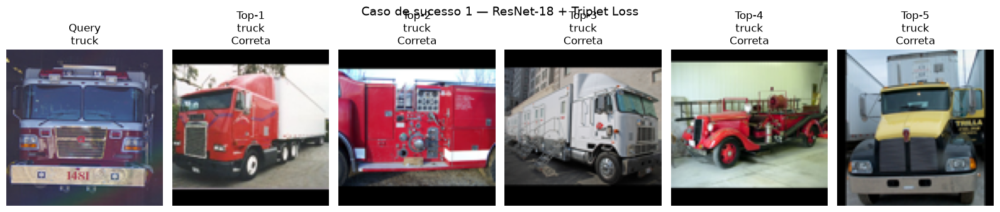

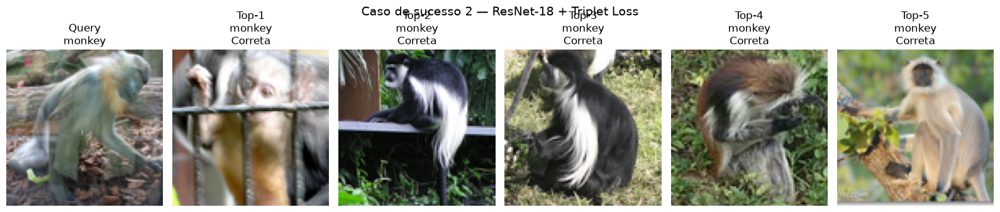

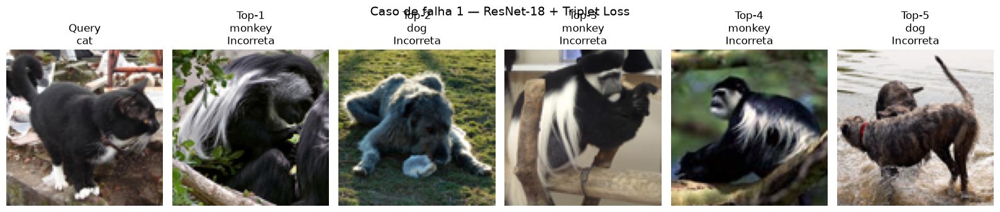

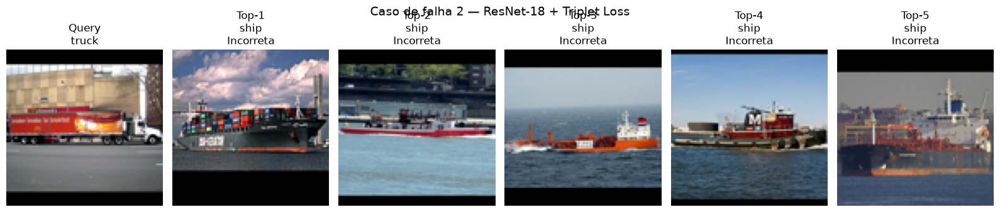

In [94]:

#Visualize Top-5 Retrieval Results
def get_test_image(original_idx):
    image_data = test_parquet.iloc[int(original_idx)]["image"]

    if isinstance(image_data, dict):
        image = Image.open(
            io.BytesIO(image_data["bytes"])
        ).convert("RGB")
    else:
        image = image_data.convert("RGB")

    return image


def show_retrieval_case(query_position, ranked_indices, gallery_indices,
                        query_labels, gallery_labels, title):
    query_original_idx = int(query_indices[query_position])
    query_label = int(query_labels[query_position])

    top5_gallery_positions = ranked_indices[query_position, :5]
    top5_original_indices = gallery_indices[top5_gallery_positions]

    fig, axes = plt.subplots(1, 6, figsize=(16, 3.5))

    axes[0].imshow(get_test_image(query_original_idx))
    axes[0].set_title(f"Query\n{class_names_stl[query_label]}")
    axes[0].axis("off")

    for rank, (ax, original_idx, gallery_position) in enumerate(
        zip(axes[1:], top5_original_indices, top5_gallery_positions), start=1
    ):
        label = int(gallery_labels[gallery_position])
        correct = label == query_label

        ax.imshow(get_test_image(original_idx))
        ax.set_title(
            f"Top-{rank}\n{class_names_stl[label]}\n"
            f"{'Correta' if correct else 'Incorreta'}"
        )
        ax.axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


selected_successes = success_indices[:2]
selected_failures = failure_indices[:2]

for i, idx in enumerate(selected_successes, start=1):
    show_retrieval_case(
        query_position=int(idx),
        ranked_indices=ranked_indices_triplet,
        gallery_indices=gallery_indices,
        query_labels=query_labels_triplet,
        gallery_labels=gallery_labels_triplet,
        title=f"Caso de sucesso {i} — ResNet-18 + Triplet Loss"
    )

for i, idx in enumerate(selected_failures, start=1):
    show_retrieval_case(
        query_position=int(idx),
        ranked_indices=ranked_indices_triplet,
        gallery_indices=gallery_indices,
        query_labels=query_labels_triplet,
        gallery_labels=gallery_labels_triplet,
        title=f"Caso de falha {i} — ResNet-18 + Triplet Loss"
    )

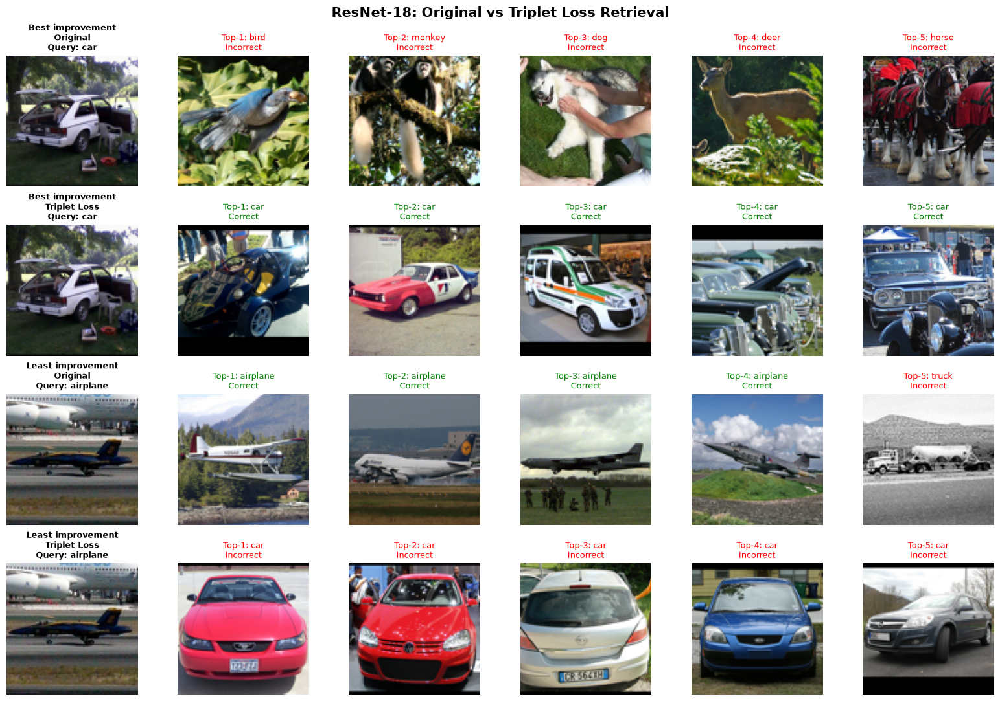

Original vs Triplet Top-5 correct matches:
Best improvement: Original=0/5, Triplet=5/5
Least improvement: Original=4/5, Triplet=0/5


In [117]:
import os
import io
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

os.makedirs("figures", exist_ok=True)

# Utilizar os resultados ja calculados no notebook
q_labels = np.asarray(query_labels_triplet)
g_labels = np.asarray(gallery_labels_triplet)

rank_original = np.asarray(ranked_indices_resnet)
rank_triplet = np.asarray(ranked_indices_triplet)

assert rank_original.shape == rank_triplet.shape
assert np.array_equal(
    np.asarray(query_labels_resnet), q_labels
)
assert np.array_equal(
    np.asarray(gallery_labels_resnet), g_labels
)

# Escolher exemplos onde Triplet melhorou e piorou o Top-5
original_correct = (
    g_labels[rank_original[:, :5]] == q_labels[:, None]
).sum(axis=1)

triplet_correct = (
    g_labels[rank_triplet[:, :5]] == q_labels[:, None]
).sum(axis=1)

improvement = triplet_correct - original_correct

best_idx = int(np.argmax(improvement))
worst_idx = int(np.argmin(improvement))

# Se ambos forem a mesma query, escolher outra
if worst_idx == best_idx:
    worst_idx = int(np.argsort(improvement)[1])

cases = [
    ("Best improvement", best_idx),
    ("Least improvement", worst_idx)
]

def read_stl_image(idx):
    item = test_parquet.iloc[int(idx)]["image"]
    if isinstance(item, dict):
        return Image.open(io.BytesIO(item["bytes"])).convert("RGB")
    return item.convert("RGB")

fig, axes = plt.subplots(4, 6, figsize=(16, 11))

for case_num, (case_title, qpos) in enumerate(cases):
    for method_num, (method_name, ranking) in enumerate([
        ("Original", rank_original),
        ("Triplet Loss", rank_triplet)
    ]):
        row = case_num * 2 + method_num
        q_class = int(q_labels[qpos])

        axes[row, 0].imshow(
            read_stl_image(query_indices[qpos])
        )
        axes[row, 0].set_title(
            f"{case_title}\n{method_name}\n"
            f"Query: {class_names_stl[q_class]}",
            fontsize=9, fontweight="bold"
        )
        axes[row, 0].axis("off")

        for k, gallery_pos in enumerate(ranking[qpos, :5]):
            gallery_pos = int(gallery_pos)
            label = int(g_labels[gallery_pos])
            correct = (label == q_class)

            ax = axes[row, k + 1]
            ax.imshow(
                read_stl_image(gallery_indices[gallery_pos])
            )
            ax.set_title(
                f"Top-{k+1}: {class_names_stl[label]}\n"
                f"{'Correct' if correct else 'Incorrect'}",
                color="green" if correct else "red",
                fontsize=9
            )
            ax.axis("off")

plt.suptitle(
    "ResNet-18: Original vs Triplet Loss Retrieval",
    fontsize=15,
    fontweight="bold"
)
plt.tight_layout()

plt.savefig(
    "figures/retrieval_original_vs_triplet.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Original vs Triplet Top-5 correct matches:")
for name, idx in cases:
    print(
        f"{name}: Original={original_correct[idx]}/5, "
        f"Triplet={triplet_correct[idx]}/5"
    )


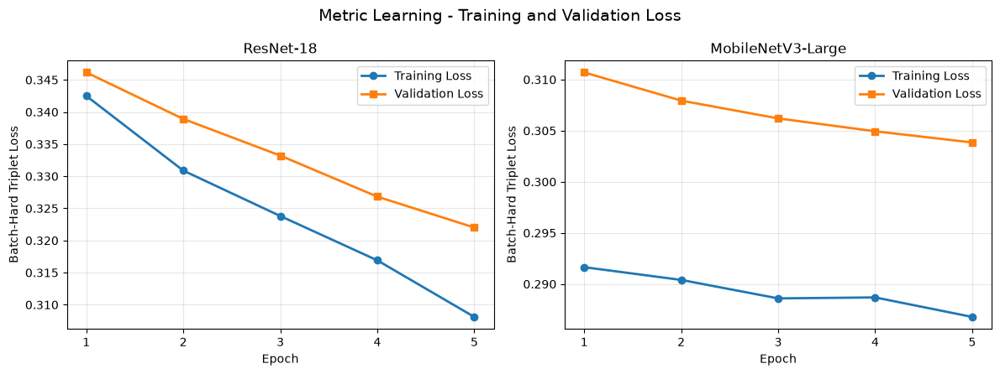

In [118]:
import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

histories = [
    ("ResNet-18", resnet_triplet_history),
    ("MobileNetV3-Large", mobilenet_triplet_history)
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (name, history) in zip(axes, histories):
    epochs = range(1, len(history["train_loss"]) + 1)

    ax.plot(
        epochs,
        history["train_loss"],
        "o-",
        label="Training Loss",
        linewidth=2
    )

    ax.plot(
        epochs,
        history["val_loss"],
        "s-",
        label="Validation Loss",
        linewidth=2
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Batch-Hard Triplet Loss")
    ax.set_xticks(list(epochs))
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    "Metric Learning - Training and Validation Loss",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    "figures/triplet_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Análise qualitativa dos resultados de recuperação de imagens

As quatro figuras apresentam exemplos de recuperação de imagens (*image retrieval*) utilizando a **ResNet-18 após a aplicação de Triplet Loss**. Em cada figura, a imagem de consulta (*Query*) encontra-se à esquerda, seguida das cinco imagens mais semelhantes recuperadas da *Gallery*, ordenadas por similaridade decrescente (Top-1 a Top-5).

**Casos de sucesso**

- **Caso de sucesso 1:** A imagem de consulta apresenta um camião branco (*truck*) numa estrada. As cinco imagens recuperadas pertencem à mesma classe, apesar das diferenças no ângulo de observação e na aparência dos veículos. Este resultado demonstra a capacidade do modelo para recuperar imagens semanticamente relevantes, mesmo quando estas não são visualmente idênticas à consulta.

- **Caso de sucesso 2:** A imagem de consulta mostra um veículo pesado vermelho e branco, identificado como *truck*. Todas as imagens recuperadas pertencem igualmente a esta classe, sugerindo que o modelo consegue reconhecer características relevantes para a categoria, apesar das variações de cor e configuração.

**Casos de falha**

- **Caso de falha 1:** A imagem de consulta apresenta um gato preto e branco (*cat*). No entanto, o modelo recupera quatro imagens de cães (*dog*) e uma de um carro (*car*). Este resultado evidencia dificuldades em distinguir determinadas categorias visuais, particularmente animais com características ou posturas semelhantes. A presença de uma imagem de um carro sugere também que a correspondência visual nem sempre reflete a classe semântica correta.

- **Caso de falha 2:** A imagem de consulta mostra a asa de um avião (*airplane*), com céu azul e nuvens como elementos predominantes do fundo. O modelo recupera quatro imagens de navios (*ship*) e uma de um pássaro (*bird*). Uma possível explicação é a influência de características visuais partilhadas, como o fundo, as cores ou a composição da imagem. Contudo, estes resultados, por si só, não permitem determinar quais as características que o modelo utilizou efetivamente para calcular a similaridade.

**Conclusão**

Os exemplos demonstram que a recuperação depende não só da classe semântica, mas também das características visuais representadas nos embeddings. Embora a ResNet-18 com Triplet Loss apresente bons resultados quantitativos, com **81,69% de Precision@1, 81,55% de Precision@5 e 77,77% de mAP**, persistem erros de recuperação entre classes visualmente distintas ou potencialmente semelhantes. Estes casos evidenciam a importância de avaliar o sistema através de métricas quantitativas e de exemplos qualitativos complementares.

# Visualização das figuras

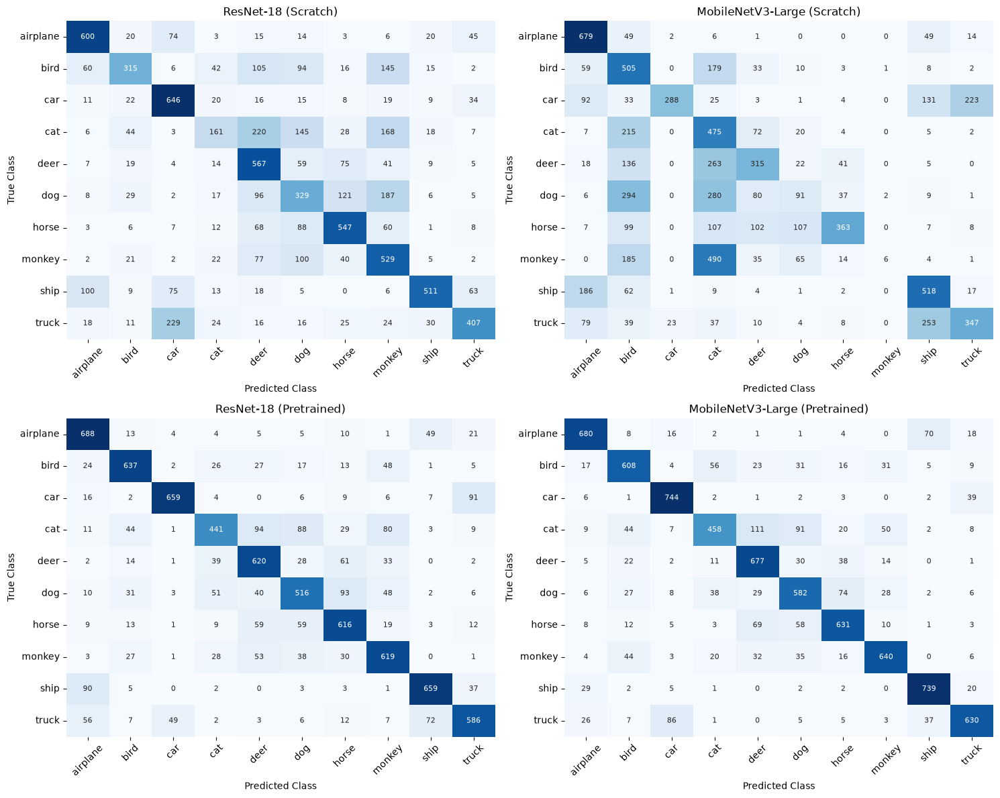

In [111]:

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("figures", exist_ok=True)

matrices = [
    ("ResNet-18 (Scratch)", cm_resnet_scratch),
    ("MobileNetV3-Large (Scratch)", cm_mobilenet_scratch),
    ("ResNet-18 (Pretrained)", cm_resnet),
    ("MobileNetV3-Large (Pretrained)", cm_mobilenet)
]

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for ax, (name, cm) in zip(axes.flat, matrices):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names_stl,
        yticklabels=class_names_stl,
        ax=ax, cbar=False,
        annot_kws={"size": 8}
    )
    ax.set_title(name, fontsize=12)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("figures/stl10_confusion_matrices.png",
            dpi=300, bbox_inches="tight")
plt.show()


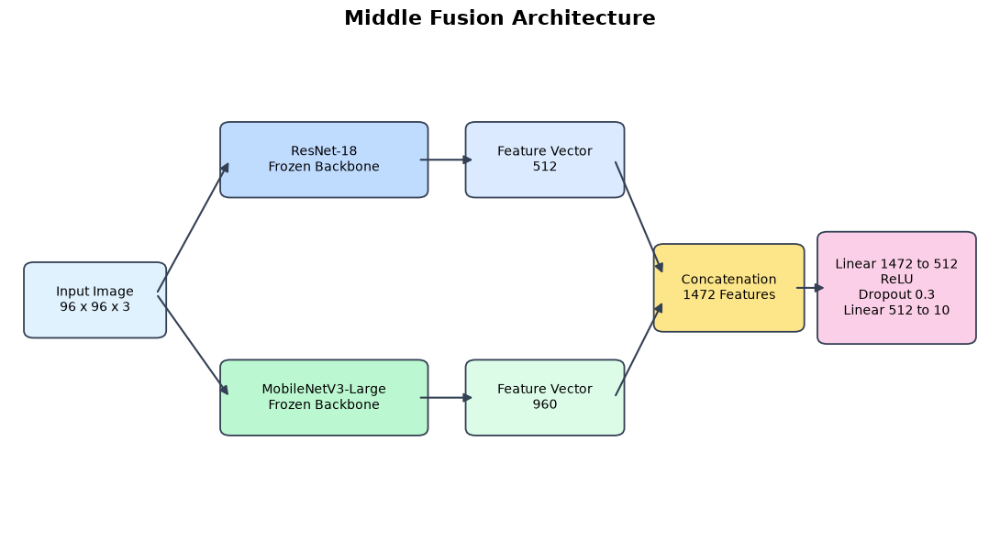

In [112]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(11, 6))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis("off")

def draw_box(x, y, w, h, label, color):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.12",
        facecolor=color,
        edgecolor="#344054",
        linewidth=1.3
    )
    ax.add_patch(box)
    ax.text(x+w/2, y+h/2, label,
            ha="center", va="center", fontsize=10)

def arrow(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>", mutation_scale=14,
        linewidth=1.5, color="#344054"
    ))

draw_box(0.3, 3.3, 1.5, 1, "Input Image\n96 x 96 x 3", "#E0F2FE")

draw_box(2.7, 5.6, 2.3, 1,
         "ResNet-18\nFrozen Backbone", "#BFDBFE")
draw_box(2.7, 1.7, 2.3, 1,
         "MobileNetV3-Large\nFrozen Backbone", "#BBF7D0")

draw_box(5.7, 5.6, 1.7, 1,
         "Feature Vector\n512", "#DBEAFE")
draw_box(5.7, 1.7, 1.7, 1,
         "Feature Vector\n960", "#DCFCE7")

draw_box(8.0, 3.4, 1.6, 1.2,
         "Concatenation\n1472 Features", "#FDE68A")

draw_box(10.0, 3.2, 1.7, 1.6,
         "Linear 1472 to 512\nReLU\nDropout 0.3\nLinear 512 to 10",
         "#FBCFE8")

arrow(1.8, 3.9, 2.7, 6.1)
arrow(1.8, 3.9, 2.7, 2.2)
arrow(5.0, 6.1, 5.7, 6.1)
arrow(5.0, 2.2, 5.7, 2.2)
arrow(7.4, 6.1, 8.0, 4.2)
arrow(7.4, 2.2, 8.0, 3.8)
arrow(9.6, 4.0, 10.0, 4.0)

ax.set_title("Middle Fusion Architecture",
             fontsize=16, fontweight="bold", pad=15)

plt.tight_layout()
plt.savefig("figures/middle_fusion_architecture.png",
            dpi=300, bbox_inches="tight")
plt.show()


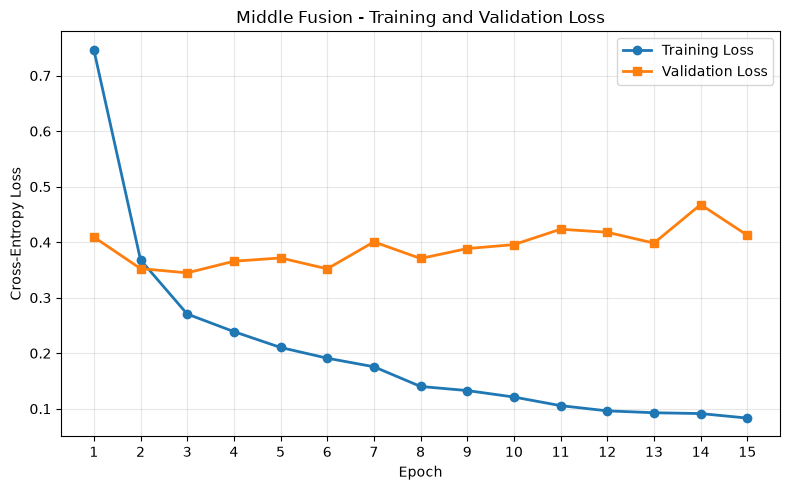

In [113]:

import matplotlib.pyplot as plt

train_loss = middle_fusion_history["train_loss"]
val_loss = middle_fusion_history["val_loss"]

epochs = range(1, len(train_loss) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, label="Training Loss",
         marker="o", linewidth=2)
plt.plot(epochs, val_loss, label="Validation Loss",
         marker="s", linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Middle Fusion - Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(epochs)
plt.tight_layout()

plt.savefig("figures/middle_fusion_loss_curves.png",
            dpi=300, bbox_inches="tight")
plt.show()


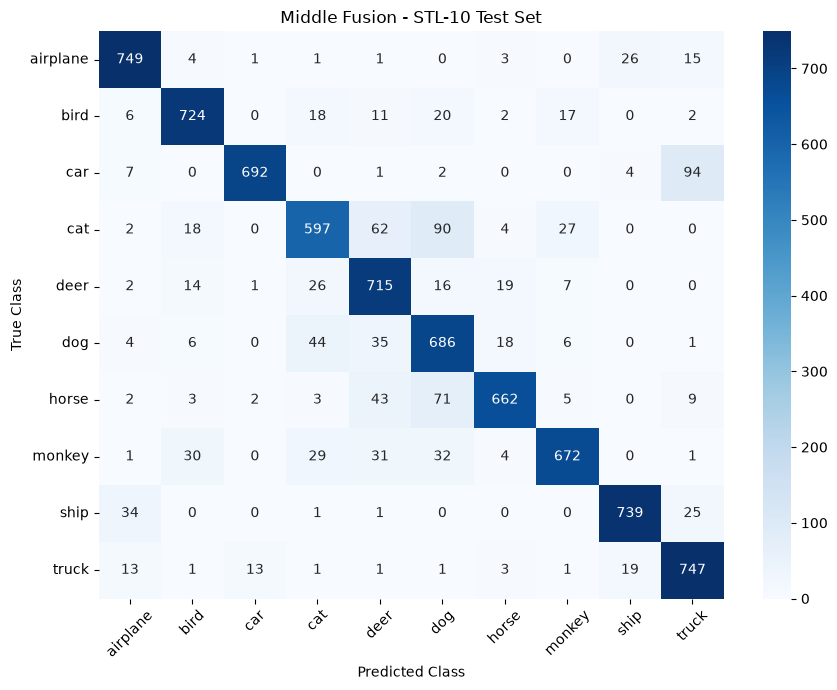

In [114]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_fusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names_stl,
    yticklabels=class_names_stl,
    annot_kws={"size": 10}
)

plt.title("Middle Fusion - STL-10 Test Set")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig("figures/middle_fusion_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()


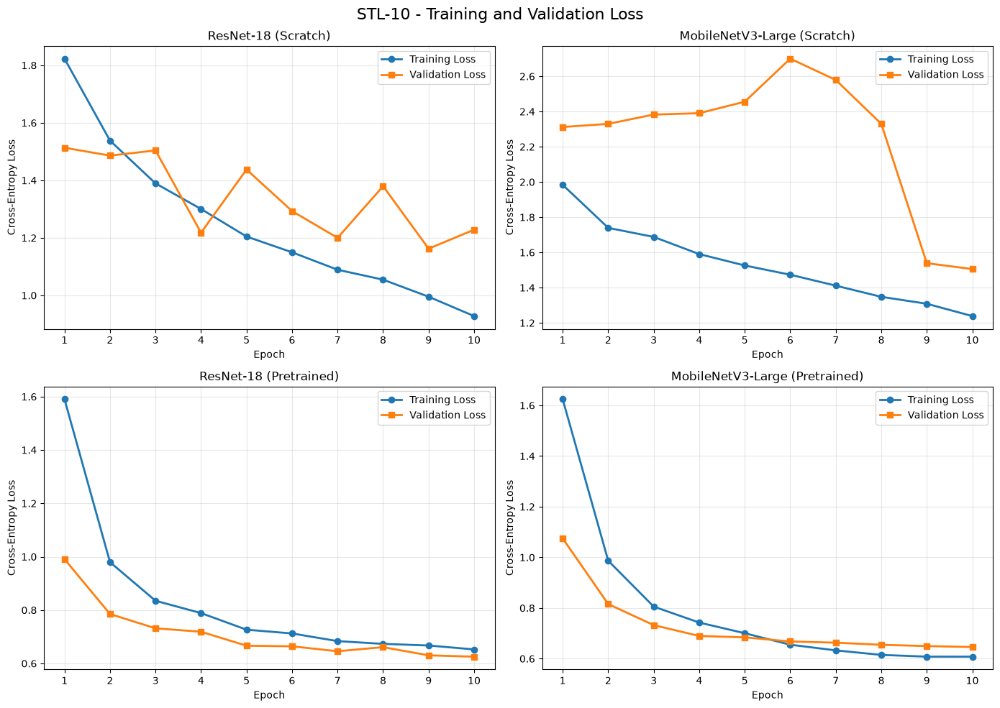

In [115]:

import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

histories = [
    ("ResNet-18 (Scratch)", resnet18_scratch_history),
    ("MobileNetV3-Large (Scratch)", mobilenet_scratch_history),
    ("ResNet-18 (Pretrained)", resnet18_history),
    ("MobileNetV3-Large (Pretrained)", mobilenet_v3_history)
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (title, history) in zip(axes.flat, histories):
    epochs = range(1, len(history["train_loss"]) + 1)

    ax.plot(
        epochs, history["train_loss"],
        marker="o", linewidth=2,
        label="Training Loss"
    )
    ax.plot(
        epochs, history["val_loss"],
        marker="s", linewidth=2,
        label="Validation Loss"
    )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-Entropy Loss")
    ax.set_xticks(list(epochs))
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(
    "STL-10 - Training and Validation Loss",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    "figures/stl10_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


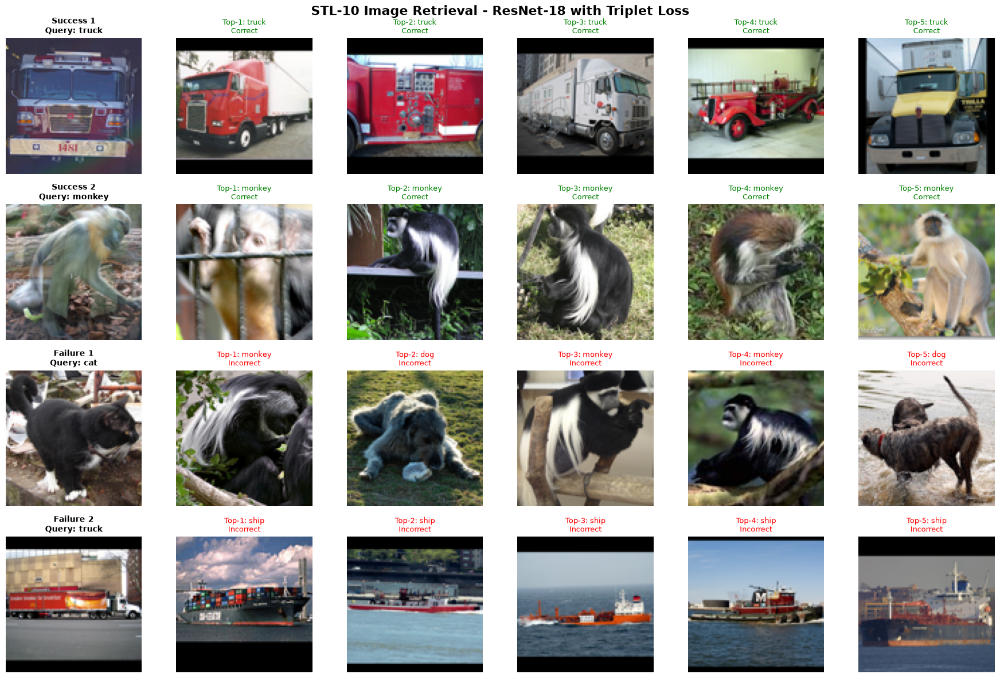

In [119]:

import os
import io
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

os.makedirs("figures", exist_ok=True)

query_labels = np.asarray(query_labels_triplet)
gallery_labels = np.asarray(gallery_labels_triplet)

top5_labels = gallery_labels[ranked_indices_triplet[:, :5]]
correct_top5 = (top5_labels == query_labels[:, None]).sum(axis=1)

success_indices = np.where(correct_top5 == 5)[0]
failure_indices = np.where(correct_top5 == 0)[0]

def get_image(idx):
    data = test_parquet.iloc[int(idx)]["image"]
    if isinstance(data, dict):
        return Image.open(io.BytesIO(data["bytes"])).convert("RGB")
    return data.convert("RGB")

selected = [
    ("Success 1", success_indices[0]),
    ("Success 2", success_indices[1]),
    ("Failure 1", failure_indices[0]),
    ("Failure 2", failure_indices[1])
]

fig, axes = plt.subplots(4, 6, figsize=(18, 12))

for row, (case_name, query_pos) in enumerate(selected):
    query_pos = int(query_pos)

    query_idx = query_indices[query_pos]
    query_label = int(query_labels[query_pos])

    axes[row, 0].imshow(get_image(query_idx))
    axes[row, 0].set_title(
        f"{case_name}\nQuery: {class_names_stl[query_label]}",
        fontsize=10, fontweight="bold"
    )
    axes[row, 0].axis("off")

    top5_positions = ranked_indices_triplet[query_pos, :5]

    for rank, gallery_pos in enumerate(top5_positions):
        gallery_idx = gallery_indices[gallery_pos]
        label = int(gallery_labels[gallery_pos])
        correct = label == query_label

        ax = axes[row, rank + 1]
        ax.imshow(get_image(gallery_idx))

        ax.set_title(
            f"Top-{rank+1}: {class_names_stl[label]}\n"
            f"{'Correct' if correct else 'Incorrect'}",
            fontsize=9,
            color="green" if correct else "red"
        )
        ax.axis("off")

fig.suptitle(
    "STL-10 Image Retrieval - ResNet-18 with Triplet Loss",
    fontsize=16, fontweight="bold"
)

plt.tight_layout(pad=0.8, w_pad=0.5, h_pad=1.2)
plt.savefig(
    "figures/retrieval_qualitative_examples.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)
plt.show()
